Persky Idan 215548512 , Golan Amir 216264333

# Lab 04 – Investigating Titanic Survival

<img src="https://upload.wikimedia.org/wikipedia/commons/6/6e/St%C3%B6wer_Titanic.jpg" alt="Historical illustration of the Titanic sinking" style="max-width:100%;height:auto;" />

**Data Science Lab 83-554 · Bar-Ilan University · Dr. Alexandra Litinsky Simanovsky**

You are preparing a short evidence-based report about the passengers in the
provided Titanic sample. **How does survival differ across passenger groups,
and how do our data preparation decisions affect what we can conclude?**

By the end, produce a small investigation with a table, a chart, three findings,
two documented preparation decisions and one limitation. We will not train a model.

| Block | Topic | Exercises | Time |
|---|---|---|---|
| 0 | Read and understand the passenger records | 1–3 | ~15 min |
| 1 | Missing values: count them and see them | 4–6 | ~15 min |
| 2 | Who survived? Counts, rates and relationships | 7–14 | ~45 min |
| 3 | Prepare missing values and check what changed | 15–19 | ~30 min |
| 4 | Recorded fares and unusual observations | 20–22 | ~15 min |
| 5 | Create representations with a meaning | 23–28 | ~30 min |
| 6 | Find the bug | 29–30 | ~10 min |
| 7 | A look ahead and scaling | 31–33 | ~25 min |
| 8 | Independent investigation | 34–35 | ~25 min |
| 9 | Working with an LLM, critically | 36–37 | ~15 min |
| 10 | Further investigations ★ (extra) | 38–40 | |

**★ = extra.** Exercises marked ★ (all of Block 10) are extra practice: do them if you finish early. Whatever you do not finish in class, you finish on your own.

**How to work**
- Prerequisites: the pandas and visualization skills from Labs 02–03. You need numpy, pandas, matplotlib, seaborn and scikit-learn.
- Each exercise shows the **expected output** (a chart, a table, or a description of the result) under an empty cell. Write code that produces it, then run the cell – your output replaces the expected one, so save your own copy and keep the original open.
- Hints are collapsed under each exercise. Try first, open them only if you are stuck.
- Where an exercise says *explain*, write your answer in a short comment or a Markdown cell, in English or Hebrew. A number from your own output is part of a good answer.
- Exercises depend on each other and run **in order, once**: if a result looks strange, restart from the first cell instead of re-running a single cell. Later exercises use `train`, `age_by_class`, `fare_band_edges`, `train_ahead`, `test_ahead`, `minmax_scaler` and `standard_scaler` from earlier ones.
- Preserve `train_raw` and `test_raw`; make explicit copies for transformations.
- A surprising result is a reason to investigate, not an instruction to delete.
- For each chart, first identify the population, the horizontal axis, the vertical axis and any grouping variables. After running it, write an observation with evidence and a limitation.
- Expected outputs were produced with pandas 3. On pandas 2.x, text columns show as `object` instead of `str`, `nan` prints as `NaN`, and tied values (such as the most common `Cabin`) can come out differently – that is fine.

**Data** (folder `data/`, next to this notebook)
- `train.csv` – 891 passengers with their observed `Survived` outcome.
- `test.csv` – 418 passengers, with the outcome withheld.

Source: the [Kaggle Titanic challenge](https://www.kaggle.com/c/titanic/data).

## The story behind the table

The Titanic sank in the North Atlantic on 15 April 1912. This lab investigates
passenger records from the Titanic dataset supplied for the
[Kaggle Titanic challenge](https://www.kaggle.com/c/titanic/data).
The question is not simply how to draw a chart. We want to understand **which
passenger groups had different observed survival rates**, what information is
missing, and how preparation choices change the data we analyse.

### What does one row represent?

One row describes **one passenger**, not one family, cabin, ticket or voyage.
Several passengers may share a ticket number. This does not make their rows
duplicates. The table is a partial set of historical records, not the complete
ship manifest and not a random sample of today's population.

For example, the first training record describes passenger 1: a 22-year-old man
travelling in third class, with one sibling/spouse recorded aboard, a recorded
fare of 7.25, and `Survived = 0`. A blank cabin means that this file contains no
cabin entry for him; it does not prove he had no cabin. Reading a row this way is
the first step before choosing a calculation.

### Why are there two files?

| File | Rows | What is available? | How we use it here |
|---|---:|---|---|
| `train.csv` | 891 | Passenger attributes and the observed `Survived` outcome | Investigate survival and learn preparation parameters |
| `test.csv` | 418 | Passenger attributes; no `Survived` column | Inspect data quality and apply the rules learned from train |

Here **train** and **test** are names inherited from a prediction challenge. We
are not training a model in this lab. The absence of `Survived` in test means the
outcome was withheld. It is not a missing-data problem to solve by filling zero,
and we cannot calculate the observed survival rate of those 418 passengers.

### Understand the columns before using them

| Column | Meaning and units | How to think about it |
|---|---|---|
| `PassengerId` | Passenger identifier | A key, not a measured quantity; an average ID has no useful passenger meaning |
| `Survived` | 0 = did not survive; 1 = survived | Binary outcome, present only in train; its mean is a survival fraction |
| `Pclass` | Ticket class: 1 = first, 2 = second, 3 = third | Ordered categories, even though pandas reads numbers |
| `Name` | Recorded passenger name | Text; distinct people may share a surname |
| `Sex` | Recorded sex, `female` or `male` | A category, not a numerical scale |
| `Age` | Age in years | Numerical; fractional ages can describe infants, and some ages are unknown |
| `SibSp` | Number of siblings/spouses aboard | A relative count, not a passenger identifier |
| `Parch` | Number of parents/children aboard | Another relative count; friends and other companions are not counted here |
| `Ticket` | Ticket number or code | An identifier that may be shared by several passengers |
| `Fare` | Recorded fare, in pounds | Numerical and often right-skewed; do not assume each entry is a per-person price |
| `Cabin` | Recorded cabin entry | Text with many blanks; no entry is different from proof of no cabin |
| `Embarked` | C = Cherbourg; Q = Queenstown; S = Southampton | Port code, a category; some entries are missing |

The values describe what was recorded. They do not explain why an entry is
missing or why a passenger survived. We will distinguish **observation**,
**possible explanation**, and **evidence we would need to check that explanation**.


## Block 0 – Read and understand the passenger records

Start with the two original files. Read a few rows, inspect their structure, and relate the stored types to the meaning of each field.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

if 'get_ipython' in globals():
    get_ipython().run_line_magic('matplotlib', 'inline')

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
# Colours for all missing-value maps.
missing_palette = ['#E9F3F2', '#1C6D70']
train_raw = pd.read_csv('data/train.csv')
test_raw = pd.read_csv('data/test.csv')
train = train_raw.copy(deep=True)
test = test_raw.copy(deep=True)
display(train.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Exercise 1 – Check the sample

Create a compact report with row count, column count, unique passenger IDs and
fully duplicated rows for each file. Confirm which file has `Survived`.
Explain why combining both files and replacing missing `Survived` with zero would
change the meaning of the data. Store the report as `sample_report`.

In [2]:
# Build the sample report with files as rows and metrics as columns
sample_report = pd.DataFrame([
    {
        'File': 'train.csv',
        'Row Count': len(train_raw),
        'Column Count': train_raw.shape[1],
        'Unique Passenger IDs': train_raw['PassengerId'].nunique(),
        'Fully Duplicated Rows': train_raw.duplicated().sum(),
        'Has Survived Column': 'Survived' in train_raw.columns
    },
    {
        'File': 'test.csv',
        'Row Count': len(test_raw),
        'Column Count': test_raw.shape[1],
        'Unique Passenger IDs': test_raw['PassengerId'].nunique() if 'PassengerId' in test_raw.columns else 0,
        'Fully Duplicated Rows': test_raw.duplicated().sum(),
        'Has Survived Column': 'Survived' in test_raw.columns
    }
]).set_index('File')

display(sample_report)


,Row Count,Column Count,Unique Passenger IDs,Fully Duplicated Rows,Has Survived Column
File,,,,,
train.csv,891,12,891,0,True
test.csv,418,11,418,0,False


<details><summary><b>Hint 1</b></summary>

Count rows and unique identifiers separately.

</details>
<details><summary><b>Hint 2</b></summary>

Compare the column names in the two files.

</details>

### Exercise 2 – Read the records and their types

Inspect the first rows of both original files, show their information summaries,
and build `type_report` comparing their column types. Identify columns present in
only one file. Name a numeric column that represents a category, and one that
represents an identifier. Explain why dtype alone does not determine the analysis.

In [3]:
display(train.head())
display(test.head())
print(train.info())
print(test.info())


# A numeric column that represents a category is "Pclass"
# An identifier column is the "survived" column
# The dtype doesn't matter when determining the analysis is because the way we read information is much different for machine.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    

<details><summary><b>Hint 1</b></summary>

Compare the two sets of column names as well as their dtypes.

</details>
<details><summary><b>Hint 2</b></summary>

Use the provided dictionary to interpret each column.

</details>

### Exercise 3 – Summarise numerical and categorical data

Display numerical descriptive statistics and categorical summaries separately
for `train_raw` and `test_raw`. Compare the age and fare ranges. Inspect counts,
unique values and common categories for `Sex`, `Embarked`, `Cabin` and `Ticket`.
Explain why the count in a summary may be smaller than the number of rows, and
why a very common ticket or a missing cabin needs interpretation before cleaning.

In [4]:
# train
print("Train numerical summary")
display(train_raw.describe())
print("Train categorical summary")
display(train_raw.select_dtypes(include=['object', 'category']).describe())

print("Train recorded category counts")
train_counts = pd.concat([
    train_raw['Sex'].value_counts(dropna=False), 
    train_raw['Embarked'].value_counts(dropna=False)
], keys=['Sex', 'Embarked'])

print("Train recorded category counts")
print(train_counts)

print("*"*40)


# test
print("Test numerical summary")
display(test_raw.describe())
print("Test categorical summary")
display(test_raw.select_dtypes(include=['object', 'category']).describe())

print("Test recorded category counts")
train_counts = pd.concat([
    train_raw['Sex'].value_counts(dropna=False), 
    train_raw['Embarked'].value_counts(dropna=False)
], keys=['Sex', 'Embarked'])

print("Train recorded category counts")
print(train_counts)



Train numerical summary


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Train categorical summary


C:\Users\idanp\AppData\Local\Temp\ipykernel_17704\1278642618.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train_raw.select_dtypes(include=['object', 'category']).describe())


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


Train recorded category counts
Train recorded category counts
Sex       male      577
          female    314
Embarked  S         644
          C         168
          Q          77
          nan         2
Name: count, dtype: int64
****************************************
Test numerical summary


,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


Test categorical summary


C:\Users\idanp\AppData\Local\Temp\ipykernel_17704\1278642618.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(test_raw.select_dtypes(include=['object', 'category']).describe())


,Name,Sex,Ticket,Cabin,Embarked
count,418,418,418,91,418
unique,418,2,363,76,3
top,"Kelly, Mr. James",male,PC 17608,B57 B59 B63 B66,S
freq,1,266,5,3,270


Test recorded category counts
Train recorded category counts
Sex       male      577
          female    314
Embarked  S         644
          C         168
          Q          77
          nan         2
Name: count, dtype: int64


<details><summary><b>Hint 1</b></summary>

Numerical and text-column summaries report different statistics.

</details>
<details><summary><b>Hint 2</b></summary>

Retain missing categories when explicitly counting values.

</details>

## Block 1 – Missing values: count them and see them

A blank is an unknown entry, not automatically zero. A table tells us how many gaps occur; bars compare their proportions; a heatmap shows their locations among passengers. Use these views together before deciding how to handle the gaps.

### Exercise 4 – Audit missingness

Write `missing_percentage(frame)`, returning a DataFrame
with `missing` and `percent` for every column, sorted by missing count. Run it
separately on `train_raw` and `test_raw`, saving `missing_report_train` and
`missing_report_test`. Identify which file contains a missing Fare. Compare missing-Age
fractions by class in train. Explain why a missing percentage alone does not
justify an imputation method. The function should also return zero percentages
for an empty input while retaining its supplied column names.

In [5]:
def missing_percentage(frame)->pd.DataFrame:
    percent = (((frame.isna().sum() / len(frame)) * 100).round(2))
    missing = frame.isna().sum()
    table = pd.DataFrame({'percent':percent,'missing':missing}, index=frame.columns)
    return table.sort_values(by="percent", ascending=False)

In [6]:
missing_report_train = missing_percentage(train_raw)
missing_report_test = missing_percentage(test_raw)

print('Missing values - train'); display(missing_report_train)
print('Missing values - test');  display(missing_report_test)

# Which file contains a missing Fare?
print('Missing Fare in train:', missing_report_train.loc['Fare', 'missing'])
print('Missing Fare in test :', missing_report_test.loc['Fare', 'missing'])
display(test_raw[test_raw['Fare'].isna()])

# Missing-Age fraction by class (train)
age_missing_by_class = (
    train_raw['Age'].isna()
    .groupby(train_raw['Pclass'])
    .agg(passengers='size', missing_age='sum', missing_fraction='mean')
    .round(3)
)
display(age_missing_by_class)

# Empty-input check
empty_report = missing_percentage(train_raw.iloc[0:0])
assert list(empty_report.index) == list(train_raw.columns)
print('Empty-input check passed')


Missing values - train


,percent,missing
Cabin,77.10,687
Age,19.87,177
Embarked,0.22,2
PassengerId,0.00,0
Name,0.00,0
Pclass,0.00,0
Survived,0.00,0
Sex,0.00,0
Parch,0.00,0
SibSp,0.00,0


Missing values - test


,percent,missing
Cabin,78.23,327
Age,20.57,86
Fare,0.24,1
Name,0.00,0
Pclass,0.00,0
PassengerId,0.00,0
Sex,0.00,0
Parch,0.00,0
SibSp,0.00,0
Ticket,0.00,0


Missing Fare in train: 0
Missing Fare in test : 1


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
152,1044,3,"Storey, Mr. Thomas",male,60.5,0,0,3701,NaN,NaN,S


,passengers,missing_age,missing_fraction
Pclass,,,
1,216,30,0.139
2,184,11,0.060
3,491,136,0.277


Empty-input check passed


<details><summary><b>Hint 1</b></summary>

Count missing entries column by column, then divide by the number of rows.

</details>
<details><summary><b>Hint 2</b></summary>

Handle zero rows before dividing. Keep test separate from train.

</details>

### Exercise 5 – Compare missing-value percentages

Use `missing_report_train` and `missing_report_test` to plot missing-value
percentages for Age, Cabin, Embarked and Fare in two side-by-side bar charts.
Use the same vertical range, 0–100%, and label the bars. Compare both the counts
and percentages: why would comparing counts alone be misleading for files of
different sizes? Do not include a synthetic Survived column in test.

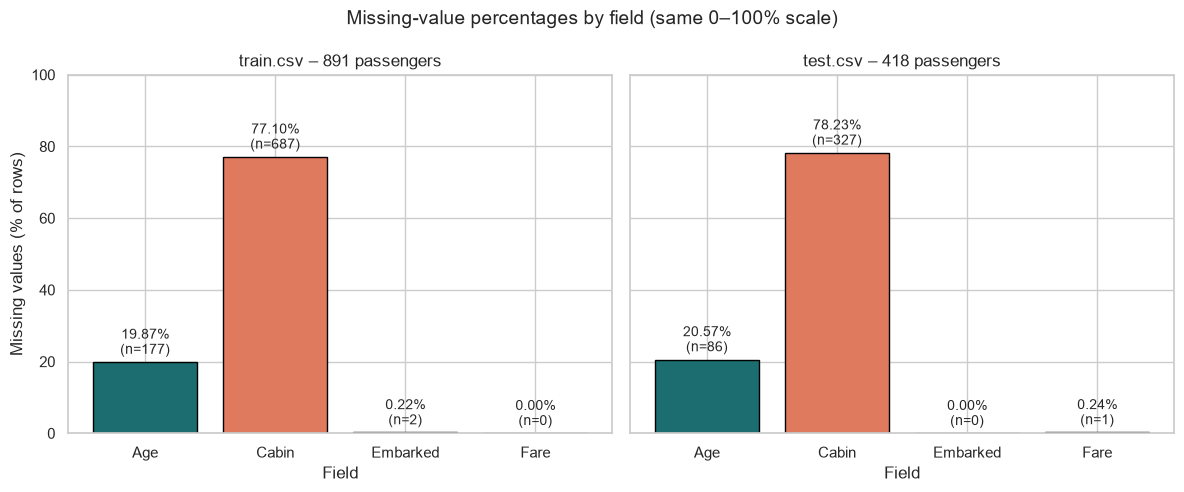

train            test        
         percent missing percent missing
Age        19.87     177   20.57      86
Cabin      77.10     687   78.23     327
Embarked    0.22       2    0.00       0
Fare        0.00       0    0.24       1

In [7]:
fields = ['Age', 'Cabin', 'Embarked', 'Fare']
reports = {'train.csv': missing_report_train, 'test.csv': missing_report_test}
colors = ['#1C6D70', '#E07A5F', '#81B29A', '#F2CC8F']

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (name, report) in zip(axes, reports.items()):
    subset = report.loc[fields]
    bars = ax.bar(fields, subset['percent'], color=colors, edgecolor='black')
    labels = [f"{p:.2f}%\n(n={m})" for p, m in zip(subset['percent'], subset['missing'])]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=10)
    ax.set_ylim(0, 100)
    ax.set_title(f"{name} – {len(train_raw) if name == 'train.csv' else len(test_raw)} passengers")
    ax.set_xlabel('Field')

axes[0].set_ylabel('Missing values (% of rows)')
fig.suptitle('Missing-value percentages by field (same 0–100% scale)', fontsize=14)
plt.tight_layout()
plt.show()

# Counts and percentages side by side
comparison = pd.concat(
    {'train': missing_report_train.loc[fields], 'test': missing_report_test.loc[fields]},
    axis=1
)
display(comparison)


<details><summary><b>Hint 1</b></summary>

Use the percentage column and identical axis limits.

</details>
<details><summary><b>Hint 2</b></summary>

Label percentages so very small missing fractions are still visible.

</details>

### Exercise 6 – See where values are missing

Draw a missing-value heatmap for each original file, side by side. Rows must
remain individual passengers in the original order; columns must be the actual
fields in that file. Make present and missing entries visually distinct, with
an explicit legend and readable field names. Identify one field that is mostly
missing and one that is missing only occasionally. What can this map show that
a percentage bar cannot? What can it not tell us about the cause of missingness?

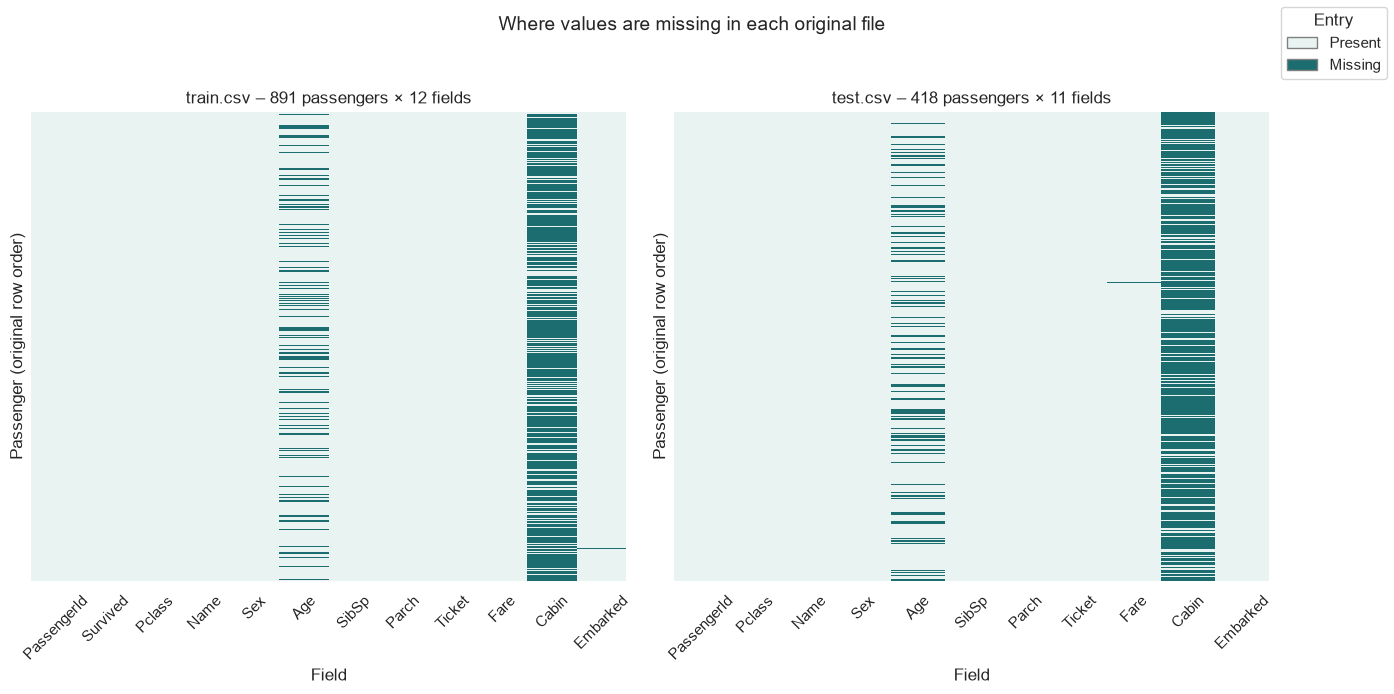

In [8]:
files = {'train.csv': train_raw, 'test.csv': test_raw}

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, (name, frame) in zip(axes, files.items()):
    mask = frame.isna().astype(int)          # 1 = missing, 0 = present; original row order
    sns.heatmap(
        mask, ax=ax, cmap=missing_palette, vmin=0, vmax=1,
        cbar=False, yticklabels=False
    )
    ax.set_title(f"{name} – {len(frame)} passengers × {frame.shape[1]} fields")
    ax.set_xlabel('Field')
    ax.set_ylabel('Passenger (original row order)')
    ax.tick_params(axis='x', rotation=45)

legend_handles = [
    Patch(facecolor=missing_palette[0], edgecolor='grey', label='Present'),
    Patch(facecolor=missing_palette[1], edgecolor='grey', label='Missing'),
]
fig.legend(handles=legend_handles, loc='upper right', title='Entry')
fig.suptitle('Where values are missing in each original file', fontsize=14)
plt.tight_layout(rect=[0, 0, 0.93, 0.95])
plt.show()


<details><summary><b>Hint 1</b></summary>

Plot a Boolean missing-value mask, not the raw ages or fares.

</details>
<details><summary><b>Hint 2</b></summary>

Use fixed values for the two colours and label their meanings.

</details>

## Block 2 – Who survived? Counts, rates and relationships

A **count** answers how many; a **rate** answers what fraction of a defined group. For a 0/1 outcome, the mean is the rate. We move from overall outcomes to sex and class, then to observed ages and port/fare combinations. These are associations in the supplied records, not controlled experiments.

### Exercise 7 – The overall outcome

Calculate the number of passengers, survivors and survival rate in `train_raw`. Explain the denominator.
Draw a count plot for the two outcomes, labelling the counts and stating which passengers are represented.

C:\Users\idanp\AppData\Local\Temp\ipykernel_17704\512701274.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=train_raw, x='Outcome', order=['Not Survived', 'Survived'], palette='Set2')


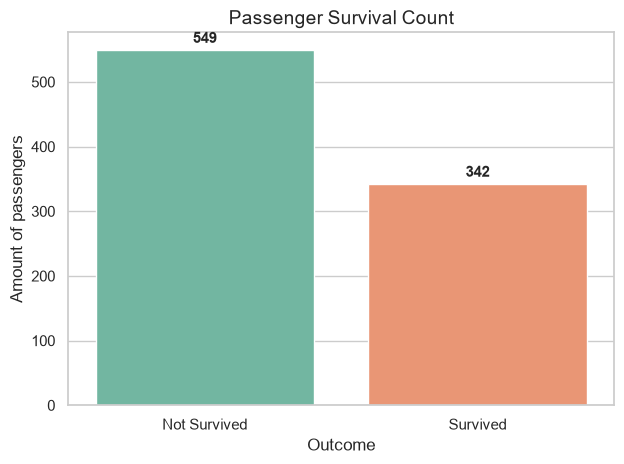

In [9]:
# Create a copy or a mapped column for display so original data isn't altered
train_raw['Outcome'] = train_raw['Survived'].map({1: 'Survived', 0: 'Not Survived'})

# Create the countplot
ax = sns.countplot(data=train_raw, x='Outcome', order=['Not Survived', 'Survived'], palette='Set2')

# Set labels and title
ax.set_xlabel('Outcome', fontsize=12)
ax.set_ylabel('Amount of passengers', fontsize=12)
ax.set_title('Passenger Survival Count', fontsize=14)

# Annotate each bar with its exact count
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Only label bars with data
        ax.annotate(
            f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height), 
            ha='center', 
            va='bottom', 
            fontsize=11, 
            fontweight='bold',
            xytext=(0, 3),  # 3 points vertical offset
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

<details><summary><b>Hint 1</b></summary>

For a 0/1 column, compare its sum and its mean.

</details>

### Exercise 8 – Sex, passenger counts and survival

Build `sex_summary` with passenger count, survivor count and survival rate by
Sex. Draw a count plot of Survived with separate colours for Sex. Then compare
the rates in the table. Explain why the tallest survivor bar alone does not
provide a within-group survival rate.

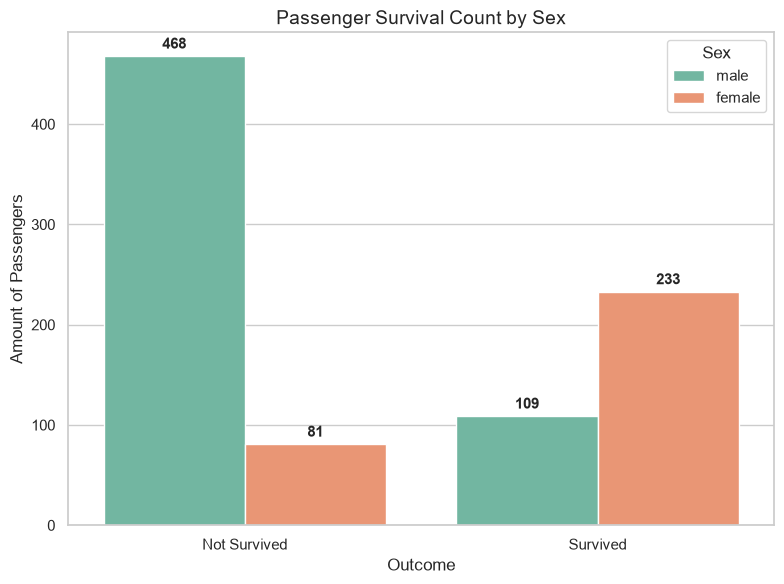

In [10]:
# Create a readable outcome column so the x-axis shows 'Not Survived' and 'Survived'
train_raw['Outcome'] = train_raw['Survived'].map({1: 'Survived', 0: 'Not Survived'})

# Create the countplot with Outcome on the x-axis and Sex as the hue
plt.figure(figsize=(8, 6))
ax = sns.countplot(
    data=train_raw, 
    x='Outcome', 
    hue='Sex', 
    order=['Not Survived', 'Survived'], 
    palette='Set2'
)

# Set labels and title
ax.set_xlabel('Outcome', fontsize=12)
ax.set_ylabel('Amount of Passengers', fontsize=12)
ax.set_title('Passenger Survival Count by Sex', fontsize=14)

# Annotate each bar with its exact count
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Only label bars with data
        ax.annotate(
            f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height), 
            ha='center', 
            va='bottom', 
            fontsize=11, 
            fontweight='bold',
            xytext=(0, 3),  # 3 points vertical offset
            textcoords='offset points'
        )

# Adjust legend and layout
plt.legend(title='Sex')
plt.tight_layout()
plt.show()

<details><summary><b>Hint 1</b></summary>

For a binary outcome use size, sum and mean together.

</details>
<details><summary><b>Hint 2</b></summary>

A countplot displays counts, not rates.

</details>

### Exercise 9 – Compare ticket classes

Create `class_summary`: passenger count, survivor count and survival rate by
`Pclass`. Plot the rates with a labelled vertical axis. Write one finding supported
by two numbers. Do not describe the result as statistically significant.
Add a separate count plot of Survived coloured by Pclass, and explain how it differs from the rate chart.

,passengers,survivors,survival_rate
Pclass,,,
1,216,136,0.630
2,184,87,0.473
3,491,119,0.242


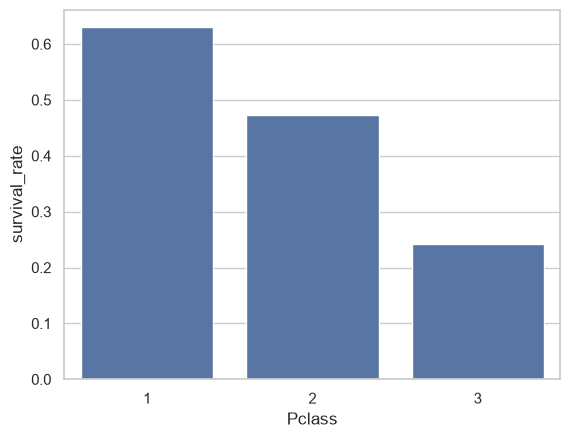

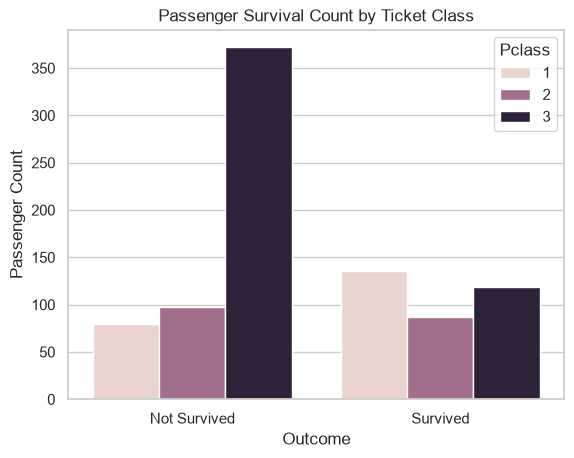

In [11]:
# Create class summary df

class_summary = (
    train_raw.groupby('Pclass')['Survived']
    .agg(passengers='count', survivors='sum', survival_rate='mean')
    .round(3)
)
display(class_summary)


# Plot the rates
sns.barplot(data = class_summary, x = 'Pclass', y = 'survival_rate' )
plt.show()

# We can see in the graph that the class that had the highest survival rate is the first class, one assumption might be that first class passengers were closer
# to the boats on the deck and probably got some kind of advantage over other classes.


sns.countplot(
    data=train_raw,
    x='Outcome',
    hue='Pclass',
    order=['Not Survived', 'Survived'],
)
plt.ylabel('Passenger Count')
plt.title('Passenger Survival Count by Ticket Class')
plt.show()

# The rate chart shows percentage of survivors in each class per class. Higher percentage doesnt mean that the class had more people.
# The second graph shows how much people actually survived in each class and even though class 1 and 3 have the same amount of people that survived, 
# the percetage graph makes it look like there are far more people that survived in class 1 than 3.


<details><summary><b>Hint 1</b></summary>

Build one grouped table with count, sum and mean.

</details>

### Exercise 10 – Look within groups

Create `sex_class_summary` with passenger counts and survival rates for each
combination of `Sex` and `Pclass`. Make one chart comparing rates across these
groups. Identify the smallest group and explain why the counts matter.

passengers  survival_rate
Sex    Pclass                           
female 1               94          0.968
       2               76          0.921
       3              144          0.500
male   1              122          0.369
       2              108          0.157
       3              347          0.135

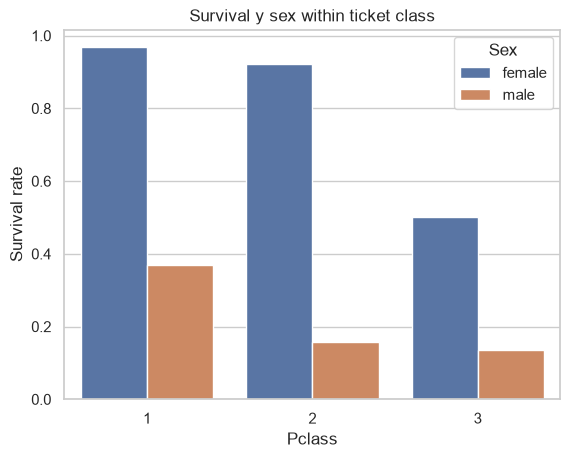

In [12]:
# Create sex_class_summary
sex_class_summary = (
    train_raw.groupby(["Sex", "Pclass"])['Survived']
    .agg(passengers='count', survival_rate='mean')
    .round(3)
)
display(sex_class_summary)


# Creating comparisson chart

sns.barplot(
    data=sex_class_summary,
    x = 'Pclass',
    y = 'survival_rate', 
    hue = 'Sex'
)
plt.ylabel('Survival rate')
plt.title('Survival y sex within ticket class')
plt.show()


<details><summary><b>Hint 1</b></summary>

Use both grouping columns together.

</details>
<details><summary><b>Hint 2</b></summary>

Reshape the rate column for a grouped bar chart.

</details>

### Exercise 11 – The distribution of observed ages

Investigate Age before filling anything. Report the number of observed and
missing ages. Plot the same observed ages with 30 bins using pandas in one panel
and seaborn in another, using identical edges and axes. Label age in years and
passenger counts. Describe the main age range and explain why this chart does
not show the age distribution of every passenger in the file.

Observed ages: 714 | Missing ages: 177


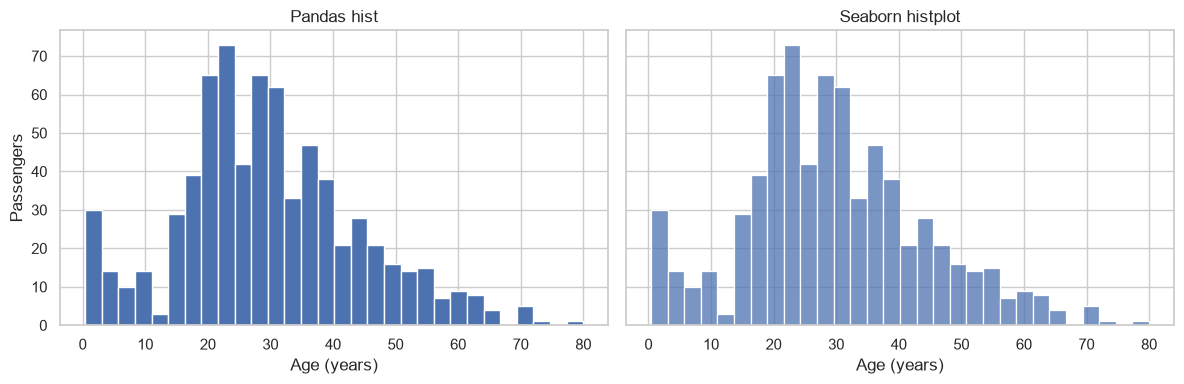

In [13]:
print(f"Observed ages: {train_raw["Age"].notna().sum()} | Missing ages: {train_raw["Age"].isna().sum()}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

train_raw["Age"].hist(ax=ax1, bins=30)
sns.histplot(data=train_raw, x="Age", bins=30, ax=ax2)

ax1.set_title("Pandas hist")
ax2.set_title("Seaborn histplot")
ax1.set_xlabel("Age (years)")
ax2.set_xlabel("Age (years)")
ax1.set_ylabel("Passengers")

plt.tight_layout()
plt.show()


# The main age range is approx 20 to 35. 
# There are 177 passengers ages missing (mostly in 3rd class), thus the distribution is not fully accurate.

<details><summary><b>Hint 1</b></summary>

Choose bin edges once and pass them to both plotting tools.

</details>
<details><summary><b>Hint 2</b></summary>

Count what was left out of the age plot.

</details>

### Exercise 12 – Age distributions by survival outcome

Make two panels of observed Age: did not survive and survived. Use shared
5-year bins from 0 to 85 and common axes. Include the number of observed ages
and the number of missing ages in each group. Describe a difference in the
distributions. Explain why comparing bar heights between these panels is not
the same as calculating survival probability at each age.

,passengers,observed_ages,missing_ages
Survived,,,
0,549,424,125
1,342,290,52


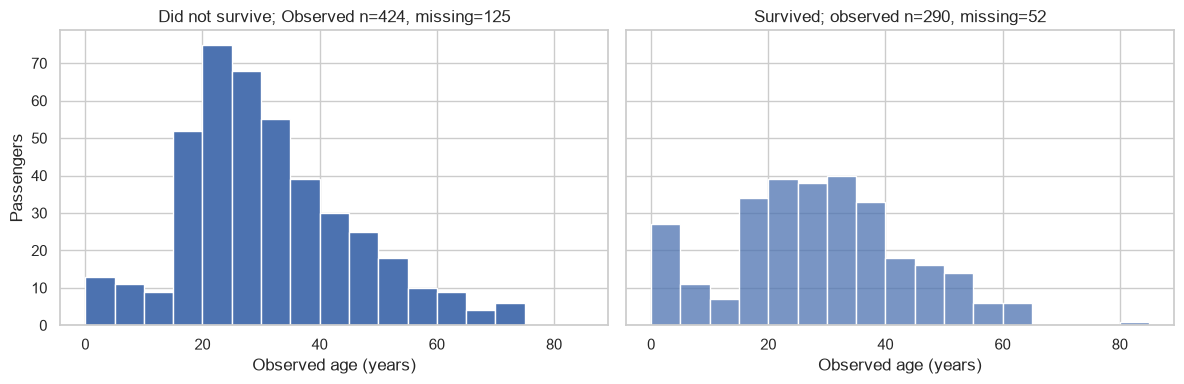

In [14]:
# Create survived panel
survived_summary = (
    train_raw.groupby('Survived')["Age"]
    .agg(passengers='size', observed_ages = 'count', missing_ages = lambda s: s.isna().sum())
)
display(survived_summary)


# Creating histograms

bins = np.linspace(0, 85, 18)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

train_raw[train_raw["Survived"] == 0]['Age'].hist(ax=ax1, bins=bins)
sns.histplot(data=train_raw[train_raw["Survived"] == 1], x="Age", bins=bins, ax=ax2)

ax1.set_title(f"Did not survive; Observed n={survived_summary["observed_ages"][0]}, missing={survived_summary["missing_ages"][0]}")
ax2.set_title(f"Survived; observed n={survived_summary["observed_ages"][1]}, missing={survived_summary["missing_ages"][1]}")
ax1.set_xlabel("Observed age (years)")
ax2.set_xlabel("Observed age (years)")
ax1.set_ylabel("Passengers")

plt.tight_layout()
plt.show()

# Young children (ages 0–5) appear more often in the survived panel, while young adults (15–35) have a much larger peak in the did-not-survive panel.
# Comparing bar heights only shows raw counts of known ages in each group, whereas survival probability requires dividing survivors by total passengers in that 
# age bin.
# Also, 177 missing ages (125 non-survivors, 52 survivors) are excluded, which skews the true counts at each age.

<details><summary><b>Hint 1</b></summary>

FacetGrid separates the data into one panel per outcome.

</details>
<details><summary><b>Hint 2</b></summary>

Use the same age bins in both panels and count missing ages separately.

</details>

### Exercise 13 – Age, class and survival in one grid

Extend the age investigation to a grid with Pclass in rows and Survived in
columns. Use the same 5-year bins and common axes throughout. Create
`age_class_summary` with group size, known ages and missing ages for all six
groups. Include the known/missing counts in panel titles. Find one comparison
that the two-panel age chart could not reveal.

passengers  observed_ages  missing_ages
Pclass Survived                                         
1      0                 80             64            16
       1                136            122            14
2      0                 97             90             7
       1                 87             83             4
3      0                372            270           102
       1                119             85            34

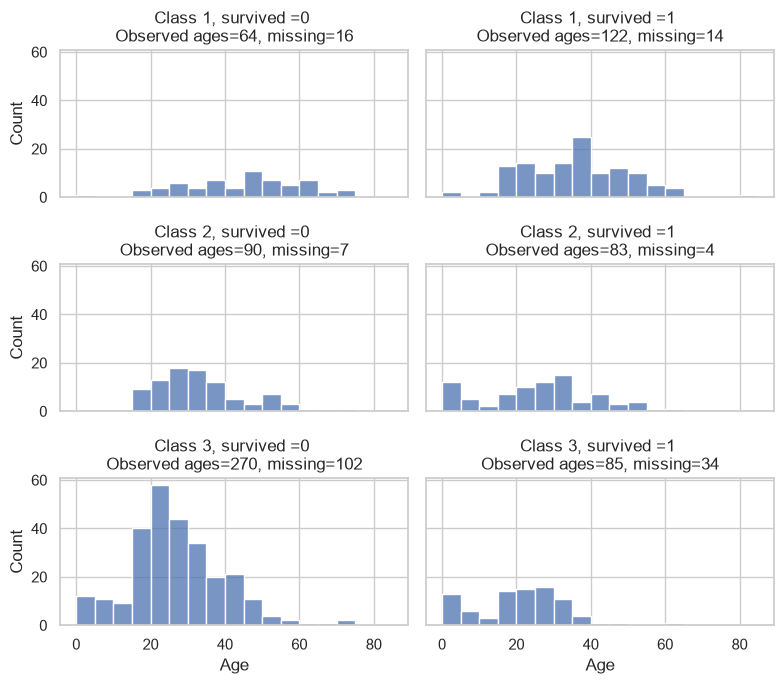

In [15]:
# Create sex_class_summary
age_class_summary = (
    train_raw.groupby(["Pclass", "Survived"])['Age']
    .agg(passengers='size', observed_ages = 'count', missing_ages = lambda s: s.isna().sum())
)
display(age_class_summary)


bins = np.linspace(0, 85, 18)
fig, axes = plt.subplots(3, 2, figsize=(8, 7), sharex=True, sharey=True)

for df_indexes, ax in zip(age_class_summary.index, axes.flatten()):

    pclass = df_indexes[0]
    survived = df_indexes[1]

    # Current subset used
    subset_used = train_raw[(train_raw["Pclass"] == pclass) & (train_raw["Survived"] == survived)]

    # Plotting histogram
    sns.histplot(data=subset_used, x="Age", bins=bins, ax=ax)
    ax.set_title(f"Class {pclass}, survived ={survived} \nObserved ages={age_class_summary.loc[df_indexes]["observed_ages"]}, missing={age_class_summary.loc[df_indexes]["missing_ages"]}")
plt.tight_layout()
plt.show()


# The two panel age chart couldnt reveal that 1st class survivors were much older (spread around 30–50) compared to 2nd and 3rd class, where survivors were much younger.

<details><summary><b>Hint 1</b></summary>

Build the summary with both grouping columns before plotting.

</details>
<details><summary><b>Hint 2</b></summary>

Set row and column orders so panel positions remain predictable.

</details>

### Exercise 14 – Port, sex, fare and survival

Investigate recorded fares by Sex within each combination of Embarked and
Survived. Use passengers with a recorded port for this chart only, and report how
many were excluded. Make `port_fare_summary` with group counts and median Fare.
Draw a grid: port in rows, survival outcome in columns, Sex on the horizontal
axis and median Fare on the vertical axis. Use one labelled bar per group,
rather than drawing every passenger as overlapping bars. Explain why this
comparison does not isolate an effect of the embarkation port.

passengers  media_fare
Embarked Survived Sex                           
C        0        female           9       14.46
                  male            66       15.05
         1        female          64       69.30
                  male            29       30.50
Q        0        female           9        7.75
                  male            38        7.75
         1        female          27        7.83
                  male             3        7.75
S        0        female          63       20.21
                  male           364        9.50
         1        female         140       26.00
                  male            77       26.00

      Sex  passengers  media_fare
0  female           9       14.46
1    male          66       15.05
      Sex  passengers  media_fare
0  female          64        69.3
1    male          29        30.5
      Sex  passengers  media_fare
0  female           9        7.75
1    male          38        7.75
      Sex  passengers  media_fare
0  female          27        7.83
1    male           3        7.75
      Sex  passengers  media_fare
0  female          63       20.21
1    male         364        9.50
      Sex  passengers  media_fare
0  female         140        26.0
1    male          77        26.0


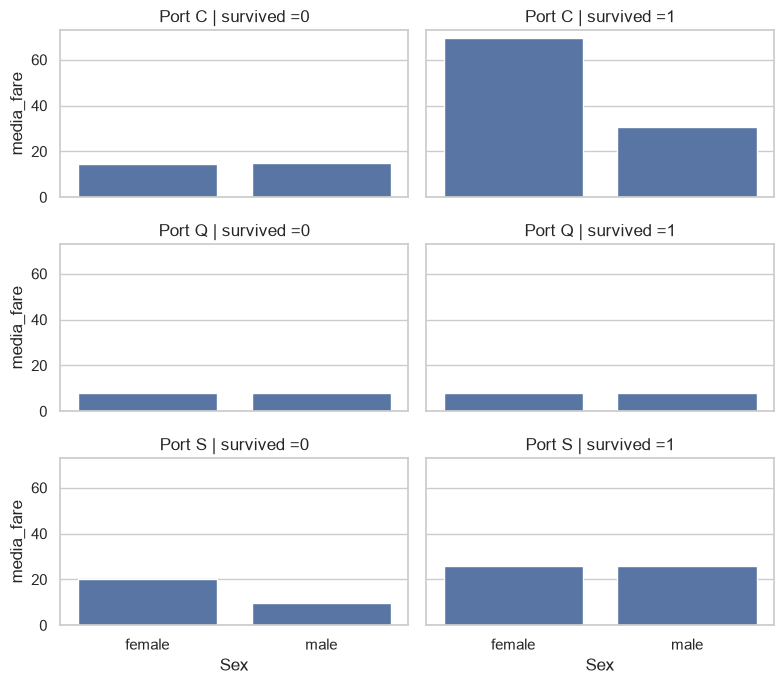

In [16]:
# Create port_fare_summary
port_fare_summary = (
    train_raw.groupby(["Embarked", "Survived", "Sex"])['Fare']
    .agg(passengers='size', media_fare='median')
    .round(2)
)
display(port_fare_summary)


# Plot the results
fig, axes = plt.subplots(3, 2, figsize=(8, 7), sharex=True, sharey=True)

for df_indexes, ax in zip(port_fare_summary.index[::2], axes.flatten()):

    port = df_indexes[0]
    survived = df_indexes[1]

    # Current subset used
    subset_used = port_fare_summary.loc[port, survived].reset_index()

    print(subset_used)
    # Plotting barplot
    sns.barplot(data = subset_used, x = "Sex", y = "media_fare",ax=ax)
    ax.set_title(f"Port {port} | survived ={survived}")
plt.tight_layout()
plt.show()

# This comparison does not isolate the effect of embarkation port because ticket class (Pclass) is a hidden variable:
# Port C had a much higher proportion of 1st class passengers (who paid higher fares and had higher survival rates), while Ports Q and S had 
# mostly 3rd class passengers.

<details><summary><b>Hint 1</b></summary>

Aggregate fares deliberately; a category repeated in raw rows is not one bar.

</details>
<details><summary><b>Hint 2</b></summary>

Keep a count beside each median and use common vertical axes.

</details>

## Block 3 – Prepare missing values and check what changed

First inspect the observed ages by class. Then compare alternative completions on independent copies. Imputation keeps passengers but does not recover their true unknown ages. We preserve raw Cabin entries and later make a CabinKnown feature rather than inventing cabins. For Embarked we compare counts before and after a stated mode-filling choice.

### Exercise 15 – Inspect age by ticket class before imputing

Before choosing an age-imputation method, build `age_by_class_observed` with
known-age counts, medians and means by class. Draw a boxplot of observed Age by
Pclass and overlay every fourth record from the rows with a known Age, using
transparent dots. State this sampling in the chart caption, and distinguish these
dots from the boxplot's separate outlier markers. Explain what the box and centre
line represent. Does the picture justify assuming all
passengers in a class have the same age?

,observed_ages,median_age,mean_age
Pclass,,,
1,186,37.0,38.23
2,173,29.0,29.88
3,355,24.0,25.14


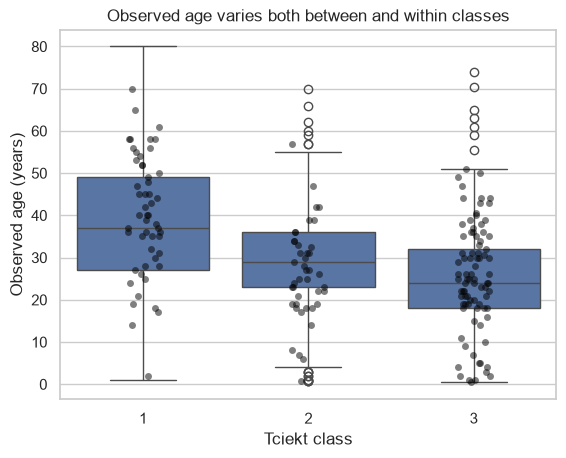

In [17]:
# Create age_by_class_observed
age_by_class_observed = (
    train_raw.groupby("Pclass")['Age']
    .agg(observed_ages='count', median_age='median', mean_age="mean")
    .round(2)
)
display(age_by_class_observed)

#Sampling ages
sampled_ages = train_raw.dropna(subset=['Age']).iloc[::4]

# Box Plotting
sns.boxplot(data=train_raw, x='Pclass', y='Age', )
sns.stripplot(data=sampled_ages, x='Pclass', y='Age', color='black', alpha=0.5)

plt.xlabel("Tciekt class")
plt.ylabel("Observed age (years)")
plt.title("Observed age varies both between and within classes")
plt.show()

# The box represents the middle 50% of ages (Q1 to Q3 / interquartile range), and the centre line is the median age.
# The transparent black dots show a sample (every 4th passenger with known age), whereas the boxplot's own markers beyond the whiskers are statistical outliers.
# This picture does NOT justify assuming all passengers in a class have the same age: although higher classes are older on average, ages vary widely within every class.

<details><summary><b>Hint 1</b></summary>

Use only recorded ages; the plotting functions omit missing Age.

</details>
<details><summary><b>Hint 2</b></summary>

Compare both the centres and spreads of the groups.

</details>

### Exercise 16 – Compare age imputation

Create `age_global` and `age_by_class`, two copies of `train_raw`.
Fill missing ages with the overall median in the first and the median of the
passenger's ticket class in the second. Preserve observed ages.
Show the two completed age distributions alongside the observed-age distribution
using identical bins. Label the number of ages in each panel and explain why raw
bar heights also reflect the number of observations. Display the medians used and count remaining missing ages.
Explain one assumption and one limitation of each approach.

Class medians used:
 Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64

Remaining missing ages -> train_raw: 177, age_global: 0, age_by_class: 0


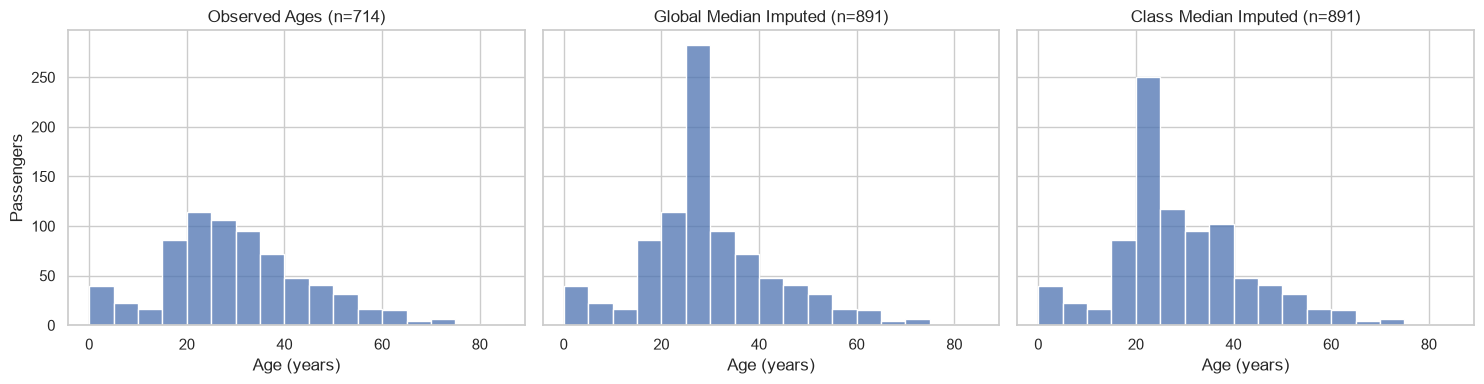

In [18]:
# Create copies
age_global = train_raw.copy()
age_by_class = train_raw.copy()

# Fill missing values
overall_median = train_raw["Age"].median()
class_medians = train_raw.groupby("Pclass")["Age"].median()

age_global["Age"] = age_global["Age"].fillna(overall_median)
age_by_class["Age"] = age_by_class["Age"].fillna(age_by_class["Pclass"].map(class_medians))

# Display medians used and remaining missing counts
print("Class medians used:\n", class_medians)
print(f"\nRemaining missing ages -> train_raw: {train_raw['Age'].isna().sum()}, "
      f"age_global: {age_global['Age'].isna().sum()}, "
      f"age_by_class: {age_by_class['Age'].isna().sum()}")

# Plot the 3 distributions
bins = np.linspace(0, 85, 18)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

sns.histplot(data=train_raw, x="Age", bins=bins, ax=ax1)
ax1.set_title(f"Observed Ages (n={train_raw['Age'].notna().sum()})")
ax1.set_xlabel("Age (years)")
ax1.set_ylabel("Passengers")

sns.histplot(data=age_global, x="Age", bins=bins, ax=ax2)
ax2.set_title(f"Global Median Imputed (n={age_global['Age'].notna().sum()})")
ax2.set_xlabel("Age (years)")

sns.histplot(data=age_by_class, x="Age", bins=bins, ax=ax3)
ax3.set_title(f"Class Median Imputed (n={age_by_class['Age'].notna().sum()})")
ax3.set_xlabel("Age (years)")

plt.tight_layout()
plt.show()

# Why raw bar heights reflect the number of observations:
# The imputed panels include all 891 passengers instead of 714, piling all 177 missing passengers into the median bin(s) and creating tall artificial spikes.
# Global median: Assumes missingness is unrelated to class/age; limitation is that it ignores class age differences and creates one massive spike at 28.
# Class median: Assumes missing ages match the typical age of their ticket class; limitation is that it still erases within-class age variation (spiking at 24, 29, and 37).

<details><summary><b>Hint 1</b></summary>

Map each passenger class to its observed median.

</details>
<details><summary><b>Hint 2</b></summary>

Use the same bins and axes so the charts are comparable.

</details>

### Exercise 17 – Document a working choice

So that everyone continues from the same table, set `train` to a copy of `age_by_class`. Keep the
original `Cabin` values and fill missing `Embarked` with the observed training mode.
Create `preparation_log` describing what changed, how many values changed, and
one limitation for each operation. Confirm known ages were not overwritten.
This is our working choice for the lab, not a claim that it is universally best.

In [19]:
train = age_by_class.copy()
train["Embarked"] = train["Embarked"].fillna(train["Embarked"].mode()[0])

preparation_log = pd.DataFrame({
    "columns": ["Age", "Embarked", "Cabin"], 
    "changed": [
        train_raw["Age"].isna().sum() - train["Age"].isna().sum(),
        train_raw["Embarked"].isna().sum() - train["Embarked"].isna().sum(),
        train_raw["Cabin"].isna().sum() - train["Cabin"].isna().sum()
    ], 
    "method": ["Training class median", "Training mode", "Retained raw"], 
    "limitation": ["Reduces within-class variation", "The true ports remain unknown", "Missing cabin records remain missing"]
})
display(preparation_log)

# Confirm known ages were not overwritten
known_mask = train_raw["Age"].notna()
print("Known ages preserved:", (train.loc[known_mask, "Age"] == train_raw.loc[known_mask, "Age"]).all())

,columns,changed,method,limitation
0,Age,177,Training class median,Reduces within-class variation
1,Embarked,2,Training mode,The true ports remain unknown
2,Cabin,0,Retained raw,Missing cabin records remain missing


Known ages preserved: True


<details><summary><b>Hint 1</b></summary>

Count changed entries from the original missing-value masks.

</details>

### Exercise 18 – Check missingness before and after preparation

Draw three aligned missing-value maps using the same training columns and
passenger order: original records, after class-median age imputation
(`age_by_class`), and after the working Age/Embarked preparation (`train`).
Use the same colours and a present/missing legend. Under the maps, report remaining
missing counts for Age, Cabin and Embarked at all three stages. Explain the
changes and why Cabin must still appear as missing. A cleaner map alone does not
prove the imputed values are correct.

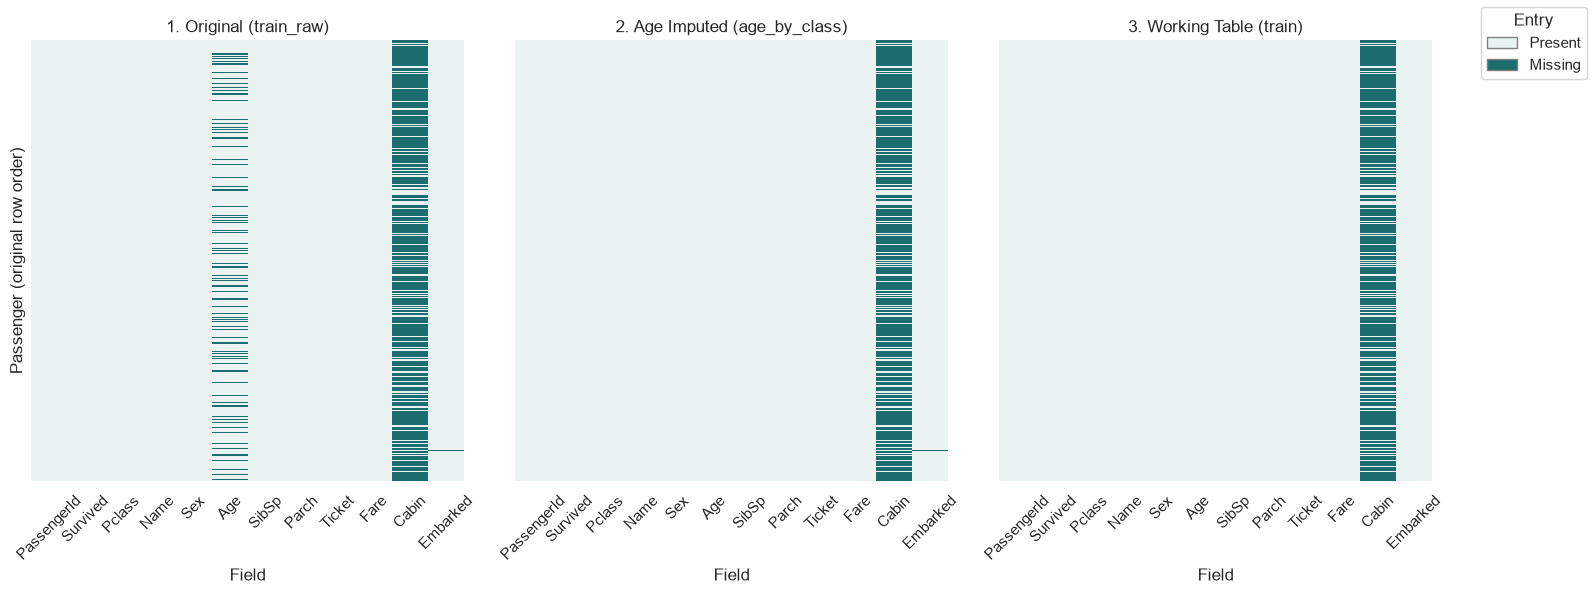

,1. Original (train_raw),2. Age Imputed (age_by_class),3. Working Table (train)
Age,177,0,0
Cabin,687,687,687
Embarked,2,2,0


In [20]:
# Original 12 training columns
cols = ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
stages = {
    '1. Original (train_raw)': train_raw[cols],
    '2. Age Imputed (age_by_class)': age_by_class[cols],
    '3. Working Table (train)': train[cols]
}

# Draw the 3 aligned missing value maps
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

for ax, (title, frame) in zip(axes, stages.items()):
    mask = frame.isna().astype(int)
    sns.heatmap(
        mask, ax=ax, cmap=missing_palette, vmin=0, vmax=1,
        cbar=False, yticklabels=False
    )
    ax.set_title(title)
    ax.set_xlabel('Field')
    ax.tick_params(axis='x', rotation=45)

axes[0].set_ylabel('Passenger (original row order)')

legend_handles = [
    Patch(facecolor=missing_palette[0], edgecolor='grey', label='Present'),
    Patch(facecolor=missing_palette[1], edgecolor='grey', label='Missing'),
]
fig.legend(handles=legend_handles, loc='upper right', title='Entry')
plt.tight_layout(rect=[0, 0, 0.92, 1])
plt.show()

# Report remaining missing counts for Age, Cabin, and Embarked at all 3 stages
missing_stages = pd.DataFrame({
    name: frame[['Age', 'Cabin', 'Embarked']].isna().sum()
    for name, frame in stages.items()
})
display(missing_stages)

# Explanation:
# After stage 2, Age missingness drops from 177 to 0; after stage 3, Embarked missingness drops from 2 to 0 (hard to spot visually on 891 rows, but confirmed by the table).
# Cabin must still appear as missing (687 rows) because we retained raw Cabin entries rather than inventing fake cabin numbers.

<details><summary><b>Hint 1</b></summary>

Select the original column order explicitly in every stage.

</details>
<details><summary><b>Hint 2</b></summary>

Use the numerical counts to verify small changes that are hard to see.

</details>

### Exercise 19 – Check the completed port categories

Compare Embarked frequencies before and after mode imputation, keeping missing
entries in the before table. Identify which category gained observations and
how many. Build a table of passenger counts and survival rates by the completed
port. Explain why filling two ports does not identify their true values.

In [21]:
before = train_raw["Embarked"].value_counts(dropna=False)
after = train["Embarked"].value_counts(dropna=False)


embarked_comparison = pd.DataFrame({"before": before, "after": after}).fillna(0).astype(int)
display(embarked_comparison)

print("Categories change:\n", embarked_comparison["after"]-embarked_comparison["before"])



# Create age_by_class_observed
emabrked_observed = (
    train.groupby("Embarked")['Survived']
    .agg(passengers='count', survival_rate='mean')
    .round(2)
)
display(emabrked_observed)

# Filling the two missing ports with the mode ('S') is just a statistical guess based on the most common port overall,
# it does not recover historical fact, as those two passengers could have actually boarded at 'C' or 'Q'.

,before,after
Embarked,,
C,168,168
Q,77,77
S,644,646
NaN,2,0


Categories change:
 Embarked
C      0
Q      0
S      2
NaN   -2
dtype: int64


,passengers,survival_rate
Embarked,,
C,168,0.55
Q,77,0.39
S,646,0.34


<details><summary><b>Hint 1</b></summary>

Keep a visible missing category when making the before table.

</details>
<details><summary><b>Hint 2</b></summary>

Compare both counts and the survival-rate denominator.

</details>

## Block 4 – Recorded fares and unusual observations

Look at the complete price distribution before flagging extremes. A long tail is a distribution property; an IQR flag is a statistical rule; a data error requires supporting evidence. An infant age and a zero fare need different interpretations.

Q1 is the 25th percentile, Q3 the 75th percentile, and IQR = Q3 − Q1. Values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are flagged for investigation, not automatically removed.

### Exercise 20 – Inspect recorded fares in both files

Before scaling or binning, plot the recorded Fare distributions of train and
test using 40 equal-width bins with common edges. Show missing counts separately.
Describe the long tail and compare mean and median. Explain why a skewed
distribution, an outlier and an invalid observation are different ideas.

,Train,Test
count,891.00,417.00
mean,32.20,35.63
std,49.69,55.91
min,0.00,0.00
25%,7.91,7.90
50%,14.45,14.45
75%,31.00,31.50
max,512.33,512.33


Missing Fare -> Train: 0, Test: 1


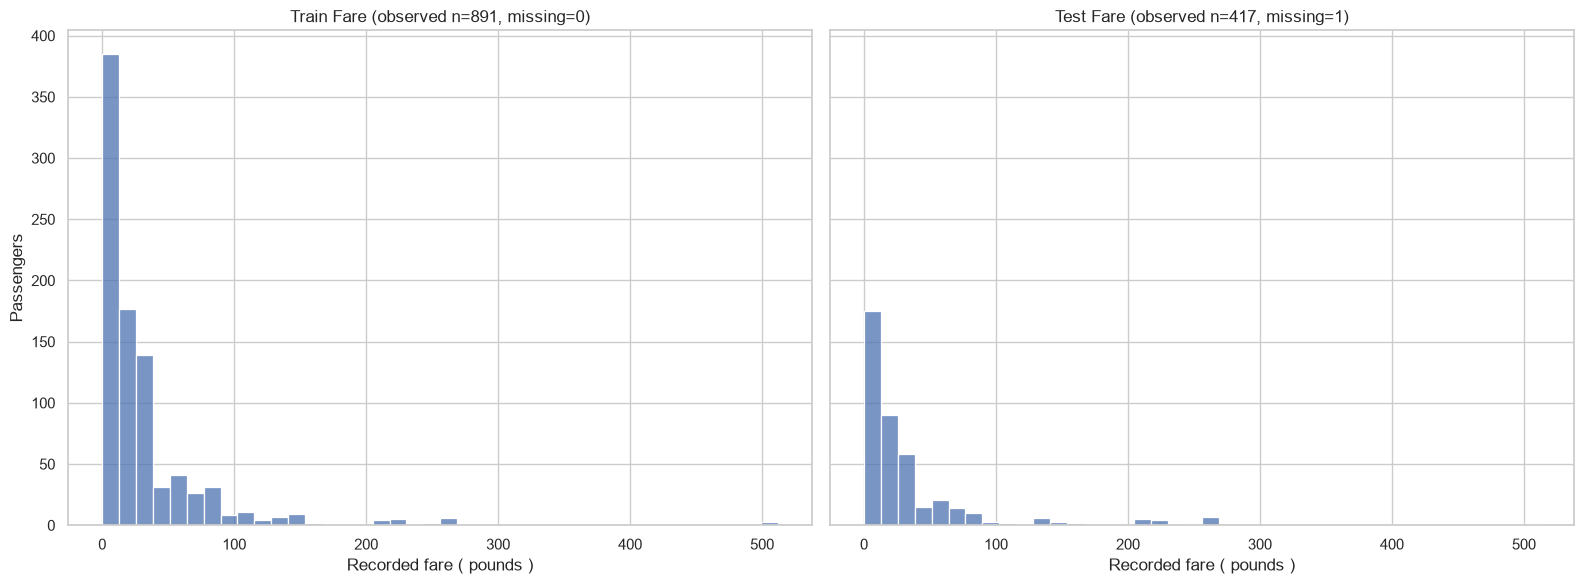

In [22]:
# Summary table + missing counts
fare_summary = pd.DataFrame({
    "Train": train["Fare"].describe(),
    "Test": test["Fare"].describe()
}).round(2)
display(fare_summary)

print(f"Missing Fare -> Train: {train['Fare'].isna().sum()}, Test: {test['Fare'].isna().sum()}")

# Plot fare distributions with 40 equal-width bins and common edges
bins = np.linspace(0, max(train["Fare"].max(), test["Fare"].max()), 41)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

sns.histplot(data=train, x='Fare', bins=bins, ax=ax1)
ax1.set_title(f"Train Fare (observed n={train['Fare'].notna().sum()}, missing={train['Fare'].isna().sum()})")

sns.histplot(data=test, x='Fare', bins=bins, ax=ax2)
ax2.set_title(f"Test Fare (observed n={test['Fare'].notna().sum()}, missing={test['Fare'].isna().sum()})")

ax1.set_ylabel("Passengers")
ax1.set_xlabel("Recorded fare ( pounds )")
ax2.set_xlabel("Recorded fare ( pounds )")

plt.tight_layout()
plt.show()

# Long tail & mean vs median: Both distributions are heavily right skewed most fares are below 30, with a long tail up to 512.33, pulling the mean far above the median.
# Skewness is a shape property of the whole distribution; an outlier is an extreme value flagged by a statistical rule (like Q3 + 1.5*IQR); 
# an invalid observation is an actual data error (a £512 luxury suite ticket is an outlier in a skewed distribution, but still a valid historical fare).

<details><summary><b>Hint 1</b></summary>

Choose common edges from the fare range, then plot only observed fares.

</details>
<details><summary><b>Hint 2</b></summary>

Missing fares need a count; a histogram cannot place them on the price axis.

</details>

### Exercise 21 – Investigate suspicious observations

Display passengers with observed `Age < 1`, passengers with `Fare == 0`,
and the five largest fares. Include passenger ID, class and ticket where relevant.
For each case, distinguish what the file shows from what would need external
verification. Do not replace or delete values automatically.

In [23]:
# Passengers with Age < 1
print("Passengers with Age < 1")
display(train_raw[train_raw["Age"] < 1])

# Passengers with Fare == 0
print("Passengers with Fare == 0")
display(train_raw[train_raw["Fare"] == 0])

# Passengers with 5 largest fares
print("Passengers with 5 largest fares")
display(train_raw.nlargest(5, 'Fare'))


# Age < 1: File shows fractional ages for infants (in months); external records are needed to verify exact birthdates.
# Fare == 0: File shows 15 men with 0 fare; external check is needed to see if they had free/staff tickets or unrecorded fares.
# 5 largest fares: File shows shared 1st-class tickets (512.33 and 263.00); external check is needed to confirm they were group/suite prices rather than typos.

Passengers with Age < 1


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Outcome
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,NaN,S,Survived
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,Survived
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,2666,19.2583,NaN,C,Survived
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,2666,19.2583,NaN,C,Survived
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,250649,14.5000,NaN,S,Survived
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C,Survived
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S,Survived


Passengers with Fare == 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Outcome
179,180,0,3,"Leonard, Mr. Lionel",male,36.0,0,0,LINE,0.0,NaN,S,Not Survived
263,264,0,1,"Harrison, Mr. William",male,40.0,0,0,112059,0.0,B94,S,Not Survived
271,272,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,LINE,0.0,NaN,S,Survived
277,278,0,2,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,239853,0.0,NaN,S,Not Survived
302,303,0,3,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,LINE,0.0,NaN,S,Not Survived
413,414,0,2,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,239853,0.0,NaN,S,Not Survived
466,467,0,2,"Campbell, Mr. William",male,NaN,0,0,239853,0.0,NaN,S,Not Survived
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0,NaN,S,Not Survived
597,598,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,LINE,0.0,NaN,S,Not Survived
633,634,0,1,"Parr, Mr. William Henry Marsh",male,NaN,0,0,112052,0.0,NaN,S,Not Survived


Passengers with 5 largest fares


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Outcome
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C,Survived
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C,Survived
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C,Survived
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S,Not Survived
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S,Survived


<details><summary><b>Hint 1</b></summary>

Use the recorded values, before imputation.

</details>
<details><summary><b>Hint 2</b></summary>

Retain identifiers so an observation can be investigated.

</details>

### Exercise 22 – Flag fares and compare the effect

Calculate the IQR fences for the original training fares. Store a Boolean mask
as `fare_flagged`, and report the number flagged. Compare mean, median and passenger
count before and after excluding flagged fares in a temporary comparison only.
Make one fare boxplot. State why the comparison does not establish that deletion
is correct. Keep every passenger in `train`.

Lower fence: -26.72, Upper fence: 65.63
Number of flagged fares: 116


,All Fares,Without Flagged
passengers,891.00,775.00
mean_fare,32.20,17.82
median_fare,14.45,13.00


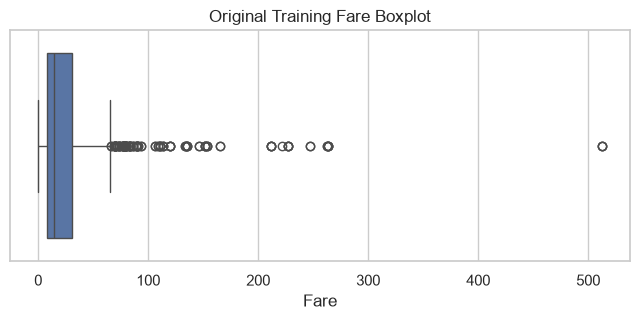

In [24]:
# Calculate IQR fences on original training fares
Q1 = train_raw["Fare"].quantile(0.25)
Q3 = train_raw["Fare"].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

# Store Boolean mask and report number flagged
fare_flagged = (train_raw["Fare"] < lower_fence) | (train_raw["Fare"] > upper_fence)
print(f"Lower fence: {lower_fence:.2f}, Upper fence: {upper_fence:.2f}")
print(f"Number of flagged fares: {fare_flagged.sum()}")

# Temporary comparison of count, mean, and median before vs. after excluding flagged fares
unflagged_fares = train_raw.loc[~fare_flagged, "Fare"]
fare_comparison = pd.DataFrame({
    "All Fares": [train_raw["Fare"].count(), train_raw["Fare"].mean(), train_raw["Fare"].median()],
    "Without Flagged": [unflagged_fares.count(), unflagged_fares.mean(), unflagged_fares.median()]
}, index=["passengers", "mean_fare", "median_fare"]).round(2)
display(fare_comparison)

# Fare boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(data=train_raw, x="Fare")
plt.title("Original Training Fare Boxplot")
plt.xlabel("Fare")
plt.show()

# Deleting flagged fares lowers the mean (from 32.20 to 17.82), but does NOT prove deletion is right: 
# those 116 flagged rows are real 1st-class and family tickets, so deleting them would throw away 13% of valid passengers and bias the data.

<details><summary><b>Hint 1</b></summary>

Create a mask rather than editing the original frame.

</details>
<details><summary><b>Hint 2</b></summary>

Compare both passenger counts and summaries.

</details>

## Block 5 – Create representations with a meaning

Keep the original columns so each new representation can be explained. Family counts, cabin-record availability and ticket frequency describe different things. Grouping prices into bands loses detail. Binary or dummy coding changes how categories are represented, not the underlying passengers.

### Exercise 23 – Recorded family size

Create `FamilySize` in `train` using the two relative-count columns and the
passenger. Compare counts and survival rates for passengers with and without
recorded relatives aboard. Explain the limits of calling passengers without
recorded relatives 'alone'.

In [25]:
# Create FamilySize (SibSp + Parch + the passenger themselves)
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1

# Compare counts and survival rates with vs. without recorded relatives
has_relatives = (train["FamilySize"] > 1).map({
    False: "No recorded relatives (FamilySize == 1)",
    True: "With recorded relatives (FamilySize > 1)"
})

family_summary = (
    train.groupby(has_relatives)["Survived"]
    .agg(passengers="count", survival_rate="mean")
    .round(3)
)
display(family_summary)

# Explanation:
# Passengers with recorded relatives had a much higher survival rate (50.6% vs. 30.4%).
# However, FamilySize == 1 only means no immediate family (SibSp/Parch) was recorded;
# they were not necessarily "alone" and may have travelled with friends, cousins, servants, or colleagues.

,passengers,survival_rate
FamilySize,,
No recorded relatives (FamilySize == 1),537,0.304
With recorded relatives (FamilySize > 1),354,0.506


<details><summary><b>Hint 1</b></summary>

Include the passenger as well as the recorded relatives.

</details>

### Exercise 24 – Was a cabin recorded?

First, compare Cabin missing counts and percentages in train and test.
Then create a column `CabinKnown` in `train` as 1 when the original cabin entry is present and 0
otherwise. Compare passenger counts and survival rates by this indicator.
Explain why 0 cannot be interpreted as 'the passenger had no cabin'.
Explain why the original Cabin text is excluded from the selected predictor table in Exercise 28, while its original entries are retained.

In [26]:
# Compare Cabin missing counts and percentages in train and test
cabin_missing = pd.DataFrame({
    "Missing Count": [train_raw["Cabin"].isna().sum(), test_raw["Cabin"].isna().sum()],
    "Missing %": [train_raw["Cabin"].isna().mean() * 100, test_raw["Cabin"].isna().mean() * 100]
}, index=["Train", "Test"]).round(2)
display(cabin_missing)

# Create CabinKnown (1 if present, 0 if missing) and compare survival rates
train["CabinKnown"] = train["Cabin"].notna().astype(int)

cabin_summary = (
    train.groupby("CabinKnown")["Survived"]
    .agg(passengers="count", survival_rate="mean")
    .round(3)
)
display(cabin_summary)

# Explanation:
# 1. CabinKnown == 0 means the cabin number is missing from the historical records, NOT that the passenger slept without a cabin.
# 2. Raw Cabin text is excluded in Ex 28 because >77% is missing and it has too many unique strings for direct modelling,
#    while the original Cabin column is kept in `train` so no raw data is lost for auditing or later deck extraction.

,Missing Count,Missing %
Train,687,77.10
Test,327,78.23


,passengers,survival_rate
CabinKnown,,
0,687,0.300
1,204,0.667


<details><summary><b>Hint 1</b></summary>

Build the indicator from the original missing-value mask.

</details>

### Exercise 25 – Ticket frequency and survival

Using original training records, distinguish (a) repeated ticket occurrences
after the first and (b) all passengers whose ticket is shared. Report their counts
and fractions. Create `ticket_analysis` with a `TicketFrequency` column counted
within train only. Build passenger-count and survival-rate summaries by frequency.
Make two charts: a count plot by frequency coloured by survival, and
two frequency-distribution panels split by survival. Explain why this feature is
not necessarily full travelling-party size or family size.

Repeated tickets after first: 210, fraction: 0.2357
All passengers on shared tickets: 344, fraction = 0.3861

 Summary by Ticket Frequency 
   TicketFrequency  PassengerCount  SurvivalRate
0                1             547      0.297989
1                2             188      0.574468
2                3              63      0.698413
3                4              44      0.500000
4                5              10      0.000000
5                6              18      0.000000
6                7              21      0.238095


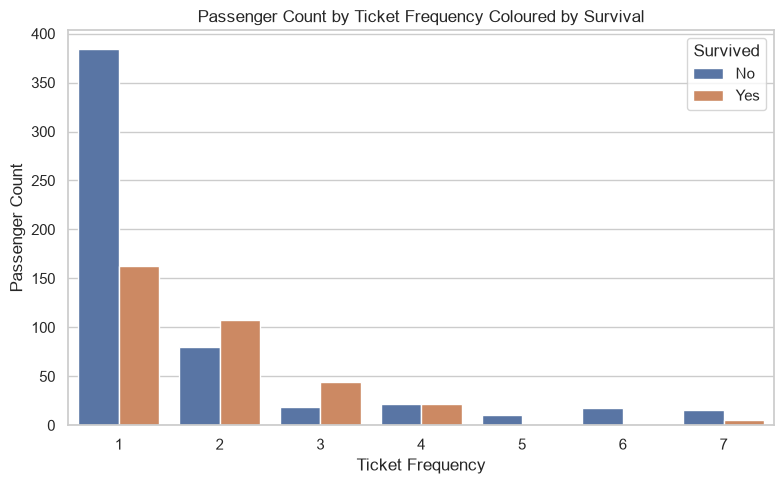

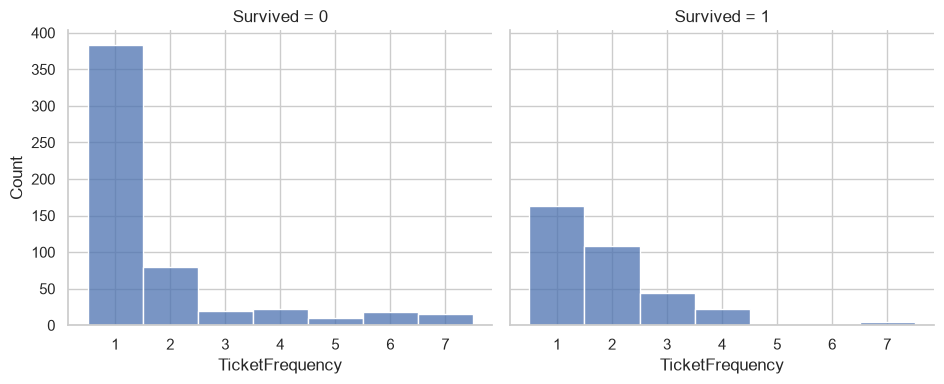

In [27]:
# Write your code here
# Lets extract the original training records
org_train = train_raw.copy(deep=True)

n_total = len(org_train)

# (a) Repeated ticket occurrences after the first
repeated_mask = org_train["Ticket"].duplicated(keep="first")
count_repeated = repeated_mask.sum()
frac_repeated = repeated_mask.mean()

# (b) All passengers whose ticket is shared
shared_mask = org_train["Ticket"].duplicated(keep=False)
count_shared = shared_mask.sum()
frac_shared = shared_mask.mean()

print(f"Repeated tickets after first: {count_repeated}, fraction: {frac_repeated:.4f}")
print(f"All passengers on shared tickets: {count_shared}, fraction = {frac_shared:.4f}")

# Creating ticket analysis
ticket_analysis = org_train.copy()
ticket_analysis["TicketFrequency"] = ticket_analysis["Ticket"].map(org_train["Ticket"].value_counts())

# Passenger-count and survival-rate
freq_summary = (
    ticket_analysis.groupby("TicketFrequency")["Survived"]
    .agg(PassengerCount="count", SurvivalRate="mean")
    .reset_index()
)
print("\n Summary by Ticket Frequency ")
print(freq_summary)

# Visualizing data
plt.figure(figsize=(8, 5))
sns.countplot(data=ticket_analysis, x="TicketFrequency", hue="Survived")
plt.title("Passenger Count by Ticket Frequency Coloured by Survival")
plt.xlabel("Ticket Frequency")
plt.ylabel("Passenger Count")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

g = sns.displot(
    data=ticket_analysis,
    x="TicketFrequency",
    col="Survived",
    discrete=True,
    height=4,
    aspect=1.2
)

<details><summary><b>Hint 1</b></summary>

duplicated() and duplicated(keep=False) answer different counting questions.

</details>
<details><summary><b>Hint 2</b></summary>

Count tickets in train only; preserve one row for each passenger.

</details>
<details><summary><b>Hint 3</b></summary>

Use integer-centred bins for an integer frequency.

</details>

### Exercise 26 – Fare bands and ordered codes

In a fresh copy `fare_bands`, divide the original training Fare into four
quantile groups. Preserve Fare, and create separate columns `FareBand` and
`FareBandCode` (ordered codes 0–3). Store the learned boundaries as `fare_band_edges`.
Show the interval-to-code mapping, group sizes and survival rates, and plot rates
by interval. Explain what information is lost by replacing a precise fare with
a band and why adjacent codes do not represent equal monetary distances.

quantile 25%: 7.9104, quantile 50%: 14.4542, quantile 75%: 31.0, quantile 100%: 512.3292
fare_band_edges: [np.float64(0.0), np.float64(7.9104), np.float64(14.4542), np.float64(31.0), np.float64(512.3292)]

Interval-to-code mapping:
   FareBandCode FareBand
0             1       Q1
2             2       Q2
7             3       Q3
1             4       Q4

Group sizes and survival rates:


,FareBand,group_size,survival_rate
0,Q1,223,0.197309
1,Q2,224,0.303571
2,Q3,222,0.454955
3,Q4,222,0.581081


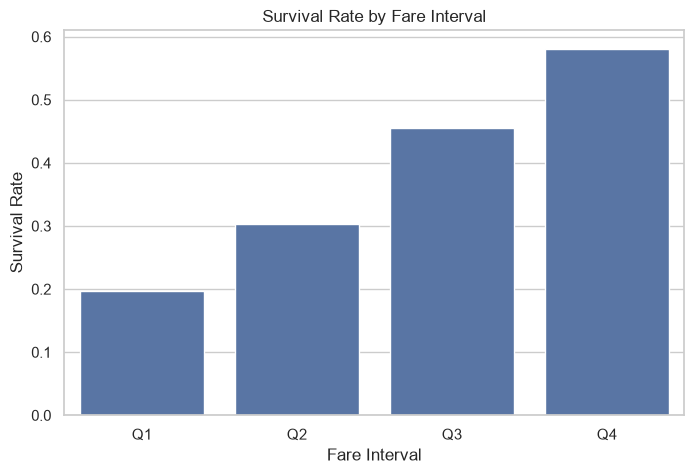

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Outcome,FareBand,FareBandCode
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Not Survived,Q1,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Survived,Q4,4
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Survived,Q2,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Survived,Q4,4
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Not Survived,Q2,2


In [28]:
# Write your code here
# Creating fare_bonds df
fare_bands = train_raw.copy(deep=True)

# Finding quantiles.
fare_Q1,fare_Q2,fare_Q3,fare_Q4  = fare_bands['Fare'].quantile(0.25),fare_bands['Fare'].quantile(0.5),fare_bands['Fare'].quantile(0.75),fare_bands['Fare'].quantile(1)
print(f"quantile 25%: {fare_Q1}, quantile 50%: {fare_Q2}, quantile 75%: {fare_Q3}, quantile 100%: {fare_Q4}")

# Creating Fareband and FareBandCode
fare_bands['FareBand'] = pd.qcut(
    fare_bands['Fare'], 
    q=4, 
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)
fare_bands['FareBandCode'] = pd.qcut(fare_bands['Fare'], q=4, labels=False) + 1

# finding the fare band edges
fare_min = fare_bands['Fare'].min()
fare_band_edges = [fare_min, fare_Q1, fare_Q2, fare_Q3, fare_Q4]
print(f"fare_band_edges: {fare_band_edges}")

# Showing interval-to-code mapping
mapping = fare_bands[['FareBandCode', 'FareBand']].drop_duplicates().sort_values('FareBandCode')
print("\nInterval-to-code mapping:")
print(mapping)

# Group sizes and survival rates
summary = fare_bands.groupby('FareBand')['Survived'].agg(
    group_size='count',
    survival_rate='mean'
).reset_index()

print("\nGroup sizes and survival rates:")
display(summary)

# Plotting survival rates by interval
plt.figure(figsize=(8, 5))
sns.barplot(data=summary, x='FareBand', y='survival_rate')
plt.title('Survival Rate by Fare Interval')
plt.xlabel('Fare Interval')
plt.ylabel('Survival Rate')
plt.show()

fare_bands.head()

<details><summary><b>Hint 1</b></summary>

Learn interval boundaries from training quantiles.

</details>
<details><summary><b>Hint 2</b></summary>

Keep a separate code column and display how each interval maps to its code.

</details>

### Exercise 27 – Make the binary mapping explicit

Create a separate column `Gender` in `train` using this mapping:
female = 1 and male = 0. Preserve the original Sex column. Show a before/after
table and verify that no category was left unmapped. Explain how this mapping
differs from treating a variable with three unordered categories as 0, 1 and 2.

In [29]:
# Write your code here
train['Gender'] = train_raw['Sex'].map({'male': 0, 'female': 1})
print(f"Gender column:")
display(train['Gender'].head())
print(f"Sex column:")
display(train['Sex'].head())

display(train['Sex'].value_counts())
display(train['Gender'].value_counts())

# The difference between each column is not the information iteself but how its handled, for an algorithm to utilate the column properly it needs it to be a bool/number. 
# In addition the way this mapping differs from treating a variable with tree unordered categories, is because one affects the other directly.

Gender column:


0    0
1    1
2    1
3    1
4    0
Name: Gender, dtype: int64

Sex column:


0      male
1    female
2    female
3    female
4      male
Name: Sex, dtype: str

Sex
male      577
female    314
Name: count, dtype: int64

Gender
0    577
1    314
Name: count, dtype: int64

<details><summary><b>Hint 1</b></summary>

Use a dictionary mapping and check missing results after mapping.

</details>
<details><summary><b>Hint 2</b></summary>

The raw category column should remain available for interpretation.

</details>

In [30]:
# A small example independent of the passenger exercises.
color_example = pd.DataFrame({'color': ['blue', 'green', 'red', 'blue']})
display(color_example)
display(pd.get_dummies(color_example, columns=['color'], drop_first=True, dtype=int))
# Blue is the omitted reference: both color_green and color_red are zero.

,color
0,blue
1,green
2,red
3,blue


,color_green,color_red
0,0,0
1,1,0
2,0,1
3,0,0


### Exercise 28 – Encode the selected columns

Create `prepared` from `Age`, `Fare`, `FamilySize`, `CabinKnown`, `Sex` and
`Embarked` in `train`. Encode the last two as dummy columns, omitting one reference
level per feature. Report columns, missing counts and row count. Exclude identifiers
and `Survived` from this predictor table. Explain what an all-zero dummy pattern means.

In [31]:
# Write your code here
# Selecting the specified columns from train (excluding identifiers and Survived)
cols = ['Age', 'Fare', 'FamilySize', 'CabinKnown', 'Sex', 'Embarked']
prepared = train[cols].copy()

# Encoding 'Sex' and 'Embarked' as dummy columns, dropping one reference level per feature
prepared = pd.get_dummies(prepared, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)

# Reporting columns, missing counts, and row count
print(f"Row count: {len(prepared)}")
print("\nColumns:")
print(list(prepared.columns))

print("\nMissing counts per column:")
print(prepared.isnull().sum())

prepared.head()

Row count: 891

Columns:
['Age', 'Fare', 'FamilySize', 'CabinKnown', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Missing counts per column:
Age           0
Fare          0
FamilySize    0
CabinKnown    0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64


,Age,Fare,FamilySize,CabinKnown,Sex_male,Embarked_Q,Embarked_S
0,22.0,7.2500,2,0,1,0,1
1,38.0,71.2833,2,1,0,0,0
2,26.0,7.9250,1,0,0,0,1
3,35.0,53.1000,2,1,0,0,1
4,35.0,8.0500,1,0,1,0,1


<details><summary><b>Hint 1</b></summary>

Use the selected columns only.

</details>
<details><summary><b>Hint 2</b></summary>

Use `get_dummies` with `drop_first=True`, not arbitrary integer labels.

</details>

## Block 6 – Find the bug
Both examples run. For each: run it, state the incorrect assumption, give a
numerical check from the data, and replace the code with a corrected version.
Do not alter the shared `train` table while investigating.


### Exercise 29 – One ticket, several passengers

A colleague says repeated ticket numbers are duplicated passengers and removes
them. Test this claim using passenger identifiers and complete-row duplicates.
Show how many passengers the proposed cleaning loses, and show one repeated ticket
with distinct passenger IDs. Preserve all distinct passenger records.

**Expected result (described, no picture or output is shown):** Provide counts and at least one concrete ticket example; no corrected output is supplied.

In [32]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.
ticket_candidate = train_raw.drop_duplicates(subset='Ticket')
print('Rows after cleaning:', len(ticket_candidate))

# Problem
# The person assumed that repeated 'Ticket' values mean duplicated rows
# In reality, multiple family members traveled on one ticket
# Dropping duplicates by 'Ticket' deletes valid, unique passengers

full_row_duplicates = train_raw.duplicated().sum()
passenger_id_duplicates = train_raw.duplicated(subset=['PassengerId']).sum()

# Show how many passengers the cleaning loses
original_count = len(train_raw)
cleaned_by_ticket_count = len(train_raw.drop_duplicates(subset='Ticket'))
passengers_lost = original_count - cleaned_by_ticket_count

print("Total original passengers:", original_count)
print("Passengers lost by proposed cleaning:", passengers_lost)

# Show one repeated ticket with distinct passenger IDs
repeated_tickets = train_raw[train_raw['Ticket'].duplicated(keep=False)].sort_values('Ticket')
example_ticket = repeated_tickets['Ticket'].iloc[0]

print("\nExample of a shared ticket with distinct passengers:")
print(train_raw[train_raw['Ticket'] == example_ticket][['PassengerId', 'Name', 'Age', 'Sex', 'Ticket', 'Survived']])

# Preserve all distinct passenger records
ticket_candidate = train_raw.drop_duplicates(subset=['PassengerId']).copy()
print("\nFinal preserved passenger count:", len(ticket_candidate))


Rows after cleaning: 681
Total original passengers: 891
Passengers lost by proposed cleaning: 210

Example of a shared ticket with distinct passengers:
     PassengerId                                               Name   Age  \
257          258                               Cherry, Miss. Gladys  30.0   
504          505                              Maioni, Miss. Roberta  16.0   
759          760  Rothes, the Countess. of (Lucy Noel Martha Dye...  33.0   

        Sex  Ticket  Survived  
257  female  110152         1  
504  female  110152         1  
759  female  110152         1  

Final preserved passenger count: 891


<details><summary><b>Hint 1</b></summary>

Compare Ticket with PassengerId before deciding what is a duplicate.

</details>

### Exercise 30 – What is the denominator?

A colleague claims this table shows survival rates by class. Explain what the
code actually calculates, prove the problem numerically, and produce a corrected
table containing both class passenger counts and within-class survival rates.

**Expected result (described, no picture or output is shown):** Explain the two denominators and compare the two calculations for one class.

In [33]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.
claimed_rates = train_raw.loc[train_raw.Survived.eq(1), 'Pclass'].value_counts(normalize=True)
print(claimed_rates.sort_index())
# Problem 
# What this actually calculates
# Denominator is the Total number of survivors across all classes
# It computes: P(Pclass = k | Survived = 1) -> The proportion of survivors from each class

# What do we need to calculate
# Denominator should be the Total number of passengers within that specific class
# It computes: P(Survived = 1 | Pclass = k) -> The percentage of people in that class who survived

# Numerical proof for Class 1
pclass1_survivors = len(train_raw[(train_raw['Pclass'] == 1) & (train_raw['Survived'] == 1)])
total_survivors = len(train_raw[train_raw['Survived'] == 1])
pclass1_total = len(train_raw[train_raw['Pclass'] == 1])

colleague_val = pclass1_survivors / total_survivors
true_val = pclass1_survivors / pclass1_total

print(f"\nProof for Class 1:")
print(f"Colleague's rate: {pclass1_survivors} / {total_survivors} = {colleague_val:.4f}")
print(f"True survival rate: {pclass1_survivors} / {pclass1_total} = {true_val:.4f}")

# Corrected table containing both class passenger counts and within-class survival rates
corrected_table = train_raw.groupby('Pclass')['Survived'].agg(
    passenger_count='count',
    survival_rate='mean'
).reset_index()

print("\nCorrected table (with within-class survival rates):")
print(corrected_table)

Pclass
1    0.397661
2    0.254386
3    0.347953
Name: proportion, dtype: float64

Proof for Class 1:
Colleague's rate: 136 / 342 = 0.3977
True survival rate: 136 / 216 = 0.6296

Corrected table (with within-class survival rates):
   Pclass  passenger_count  survival_rate
0       1              216       0.629630
1       2              184       0.472826
2       3              491       0.242363


<details><summary><b>Hint 1</b></summary>

Ask which rows survive the filter and what normalize=True divides by.

</details>

## Block 7 – A look ahead and scaling
When preparing data for prediction, estimate imputation values from the training
observations. Apply those same values to new data. Recalculating a median separately
for test changes the rule; using the test data to choose a training median uses
information from the evaluation data. We demonstrate this principle without a model.

This small example uses a global median to make the train/apply distinction clear;
it does not replace the class-median working choice earlier in the lab.


### Exercise 31 – Learn once, apply the same rule

Using the original files, compute one age median from `train_raw` only.
Create `train_ahead` and `test_ahead`, independent copies with missing ages filled
using that same value. Confirm that neither copy has missing ages and that all known
ages are unchanged. Explain why the median must not be estimated from both files.
Do not use the unknown test outcomes or replace the earlier `train` table.

In [34]:
# Write your code here
train_ahead = train_raw.copy(deep=True)
test_ahead = test_raw.copy(deep=True)

# getting the median of each file
train_median = train_ahead['Age'].median(skipna=True)
test_median = test_ahead['Age'].median(skipna=True)
print(f"Train median: {train_median} \nTest Median: {test_median}")
print(f" Missing amount of ages: \ntrain: {train_ahead['Age'].isna().sum()} \nTest: {test_ahead['Age'].isna().sum()}")
train_ahead['Age'] = train_ahead['Age'].fillna(train_median)
test_ahead['Age'] = test_ahead['Age'].fillna(test_median)

print(f" Missing amount of ages after filling null: \ntrain: {train_ahead['Age'].isna().sum()} \nTest: {test_ahead['Age'].isna().sum()}")

# The median must not be estimated in both files since each section could vary and influence our data heavily.

Train median: 28.0 
Test Median: 27.0
 Missing amount of ages: 
train: 177 
Test: 86
 Missing amount of ages after filling null: 
train: 0 
Test: 0


<details><summary><b>Hint 1</b></summary>

Calculate the median once before filling either copy.

</details>

### Scaling changes the numerical scale
`Age` is measured in years; `Fare` is a recorded price. Their ranges differ.
Some models use distances or penalties sensitive to these numerical scales.
Scaling can help those models; it does not itself demonstrate better predictions.
We will not train a model here.

- **Min–Max:** `(x - training_min) / (training_max - training_min)`.
  Non-constant training features map to [0, 1]. A new observation outside the
  training range can map below 0 or above 1.
- **Standardization:** `(x - training_mean) / training_std`.
  Non-constant training features have mean 0 and population standard deviation 1.
  `StandardScaler` uses population SD (`ddof=0`); pandas defaults to `ddof=1`.

These transformations preserve ordering and distribution shape for these
non-constant columns. They do not make skewed fares normally distributed, remove
outliers, fill missing values, or turn a negative scaled age into a negative real age.
Both methods are influenced by extreme values. We keep the unscaled tables.

**Given example:** fit learns parameters; transform applies them.
`fit_transform` performs both on the same training input.


In [35]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

toy = pd.DataFrame({'value': [10.0, 20.0, 30.0]})
toy_minmax = MinMaxScaler()
toy_standard = StandardScaler()
display(pd.DataFrame({
    'original': toy.value,
    'minmax': toy_minmax.fit_transform(toy).ravel(),
    'standardized': toy_standard.fit_transform(toy).ravel()}))
# For a new value, reuse the fitted training scaler: do not fit again.
print('New value 40 on the learned Min-Max scale:',
      toy_minmax.transform(pd.DataFrame({'value': [40.0]})).item())

,original,minmax,standardized
0,10.0,0.0,-1.224745
1,20.0,0.5,0.000000
2,30.0,1.0,1.224745


New value 40 on the learned Min-Max scale: 1.5


### Exercise 32 – Compare two scales on Titanic

Use `train_ahead` from Exercise 31, where missing ages have already
been filled. Create `scale_train` as an independent copy of its `Age` and `Fare`
columns. Confirm it has no missing values. Do not scale identifiers or `Survived`.

Fit `MinMaxScaler` and `StandardScaler` on `scale_train` only, storing them as
`minmax_scaler` and `standard_scaler`. Keep the results in DataFrames
`train_minmax` and `train_standard`, preserving the index and column names.
Make a summary with min, max, mean and population standard deviation for each
feature in the original and both transformed tables. Plot a 2-row, 3-column grid:
one row per feature, original/Min–Max/standardized in columns. Use 15 histogram
bins in each panel and label each scale. Explain what changed and why the fare
distribution did not become bell-shaped. Do not round values before checking.

Confirmation on non missin values: 
Age     0
Fare    0
dtype: int64
Summary Statistics:
        Dataset Feature       Min         Max          Mean  Std (pop)
0      Original     Age  0.420000   80.000000  2.936158e+01  13.012388
1      Original    Fare  0.000000  512.329200  3.220421e+01  49.665534
2        MinMax     Age  0.000000    1.000000  3.636791e-01   0.163513
3        MinMax    Fare  0.000000    1.000000  6.285843e-02   0.096941
4  Standardized     Age -2.224156    3.891554  2.272780e-16   1.000000
5  Standardized    Fare -0.648422    9.667167  3.987333e-18   1.000000


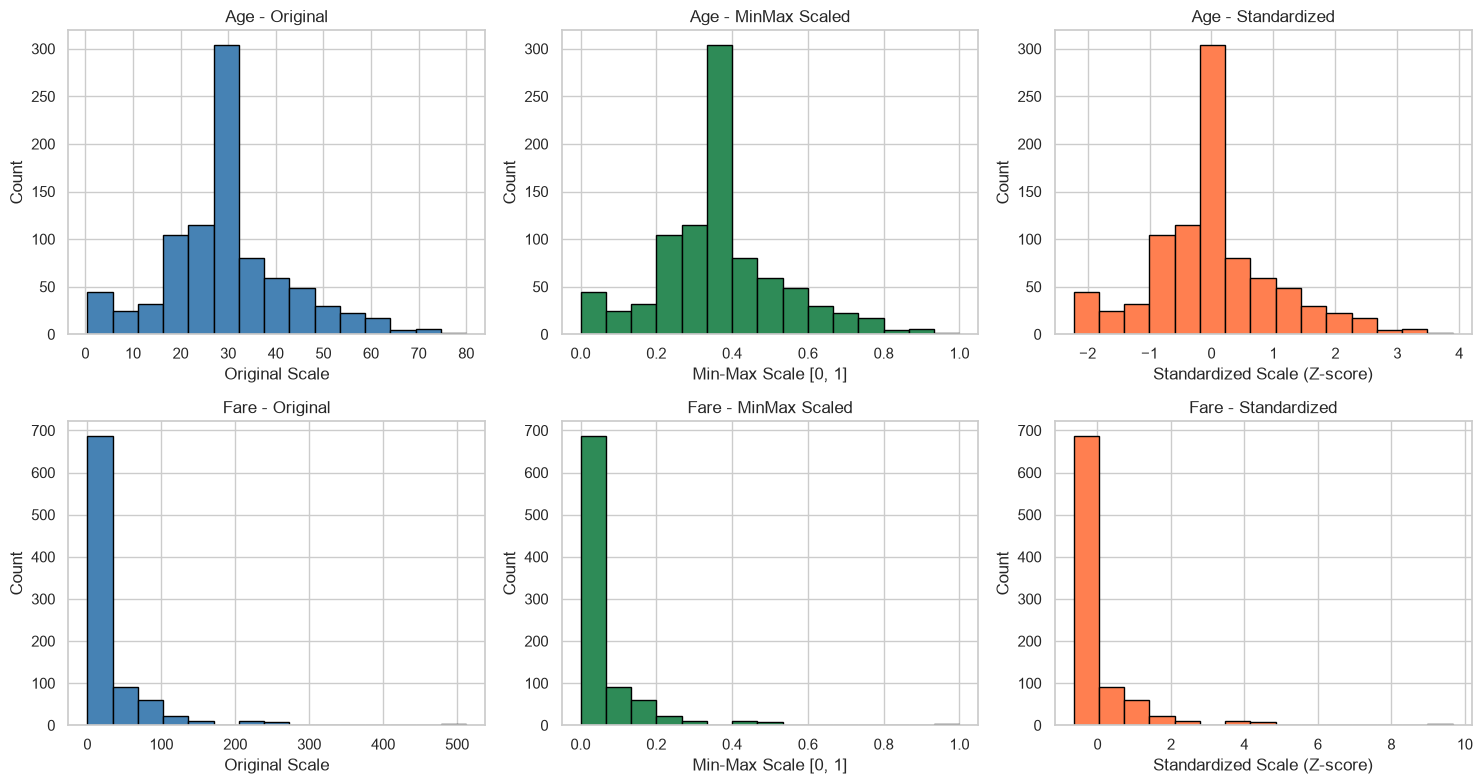

In [36]:
# Write your code here
# Copy the dataset and insuring nothing is missing
cols = ['Age','Fare']
scale_train = train_ahead[cols].copy(deep=True)
print(f"Confirmation on non missin values: \n{scale_train.isna().sum()}")

# Save scalers and fit the transformation
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()
train_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(scale_train),
    columns=cols,
    index=scale_train.index
)
train_standard = pd.DataFrame(
    standard_scaler.fit_transform(scale_train),
    columns=cols,
    index=scale_train.index
)
# We save the information we gathered
datasets = {
    'Original': scale_train,
    'MinMax': train_minmax,
    'Standardized': train_standard
}

summary_rows = []
for name, df in datasets.items():
    for col in cols:
        summary_rows.append({ # We append a dictionary with information those are our columns, while the lits are the rows.
            'Dataset': name,
            'Feature': col,
            'Min': df[col].min(),
            'Max': df[col].max(),
            'Mean': df[col].mean(),
            'Std (pop)': df[col].std(ddof=0)
        })
# printing the summary
summary_df = pd.DataFrame(summary_rows)
print("Summary Statistics:")
print(summary_df)
# Starting the plotting section
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
for row_idx, feature in enumerate(cols):
    # Column 0: Original
    axes[row_idx, 0].hist(scale_train[feature], bins=15, edgecolor='black', color='steelblue')
    axes[row_idx, 0].set_title(f"{feature} - Original")
    axes[row_idx, 0].set_xlabel("Original Scale")
    axes[row_idx, 0].set_ylabel("Count")

    # Column 1: Min-Max
    axes[row_idx, 1].hist(train_minmax[feature], bins=15, edgecolor='black', color='seagreen')
    axes[row_idx, 1].set_title(f"{feature} - MinMax Scaled")
    axes[row_idx, 1].set_xlabel("Min-Max Scale [0, 1]")
    axes[row_idx, 1].set_ylabel("Count")

    # Column 2: Standardized
    axes[row_idx, 2].hist(train_standard[feature], bins=15, edgecolor='black', color='coral')
    axes[row_idx, 2].set_title(f"{feature} - Standardized")
    axes[row_idx, 2].set_xlabel("Standardized Scale (Z-score)")
    axes[row_idx, 2].set_ylabel("Count")

plt.tight_layout()
plt.show()


<details><summary><b>Hint 1</b></summary>

Use fit_transform only on training features; wrap its array output in a DataFrame.

</details>
<details><summary><b>Hint 2</b></summary>

For the standard deviation check, specify ddof=0.

</details>
<details><summary><b>Hint 3</b></summary>

Compare histogram shapes as well as their horizontal-axis values.

</details>

### Exercise 33 – Apply the learned scales to new passengers

Create `scale_test` from `test_ahead[['Age', 'Fare']]`. Exercise 31
already filled test ages using the training age median. Fill the one missing
test fare with the median of `train_raw.Fare`, then use only `transform` with
the two fitted scalers. Store DataFrames `test_minmax` and `test_standard`.

Report row counts and missing-value counts. Count test values outside [0, 1] in
each Min–Max feature, and display any such passenger IDs with their original and
scaled values. Compare the test standardized means with the training means.
Explain why an out-of-range Min–Max result or a nonzero standardized test mean
does not automatically indicate an error. Preserve original passenger data.

In [37]:
# Write your code here
scale_test = test_ahead[['Age','Fare']].copy(deep=True)
test_raw_median = test_raw['Fare'].median()
test_raw['Fare'].fillna(test_raw_median)

minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

test_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(scale_test),
    columns=['Age','Fare'],
    index=scale_test.index
)
test_standard = pd.DataFrame(
    standard_scaler.fit_transform(scale_test),
    columns=['Age','Fare'],
    index=scale_test.index
)

print(f"Row counts: \nScale_test {len(scale_test)} \nTest_minmax {len(test_minmax)}\n test_standard {len(test_standard)}")
print(f"Missing values: \nScale_test\n {scale_test.isna().sum()} \nTest_minmax\n {test_minmax.isna().sum()}\n test_standard\n {test_standard.isna().sum()}")

age_out = (test_minmax['Age'] < 0) | (test_minmax['Age'] > 1)
fare_out = (test_minmax['Fare'] < 0) | (test_minmax['Fare'] > 1)

print(f"\nValues outside [0, 1] in Min-Max 'Age': {age_out.sum()}")
print(f"Values outside [0, 1] in Min-Max 'Fare': {fare_out.sum()}")

# Display passenger IDs with original and scaled values for Age outliers
age_outliers = pd.DataFrame({
    'PassengerId': test_ahead.loc[age_out, 'PassengerId'],
    'Age_original': scale_test.loc[age_out, 'Age'],
    'Age_minmax': test_minmax.loc[age_out, 'Age']
})
print("\nPassengers with out-of-range Age:")
print(age_outliers)


Row counts: 
Scale_test 418 
Test_minmax 418
 test_standard 418
Missing values: 
Scale_test
 Age     0
Fare    1
dtype: int64 
Test_minmax
 Age     0
Fare    1
dtype: int64
 test_standard
 Age     0
Fare    1
dtype: int64

Values outside [0, 1] in Min-Max 'Age': 0
Values outside [0, 1] in Min-Max 'Fare': 0

Passengers with out-of-range Age:
Empty DataFrame
Columns: [PassengerId, Age_original, Age_minmax]
Index: []


<details><summary><b>Hint 1</b></summary>

Use the already fitted objects, not new scaler instances.

</details>
<details><summary><b>Hint 2</b></summary>

Inspect the original values for rows outside the training range.

</details>

## Block 8 – Independent investigation
Choose a question using `FamilySize` or `CabinKnown` and at least one of `Sex` or
`Pclass`. Use the lab's working table `train` and preserve all 891 passengers.
Your conclusion must describe an association rather than establish a cause.


### Exercise 34 – Prepare your evidence

State your question in Markdown. Create `final_table` containing passenger
counts and survival rates for your chosen groups. Check that group counts sum to
the full training sample, then create one chart answering your question.
Label its axes and explain the denominator of each rate.
Different questions and charts are acceptable.

**Expected result (described, no picture or output is shown):** One grouped table with counts and rates, a total-count check, and one labelled chart.

### Investigation Question:
**"Did the Titanic's elite VIP protect male passengers from doom, or did everyone sank equally regardless of the cabin?"**
*(Variables used: `CabinKnown` and `Sex` from `train`)*

--- Final Table ---
      Sex  CabinKnown  passenger_count  survival_rate
0  female           0              217       0.654378
1  female           1               97       0.938144
2    male           0              470       0.136170
3    male           1              107       0.420561

Total passengers: 891 (Expected: 891)


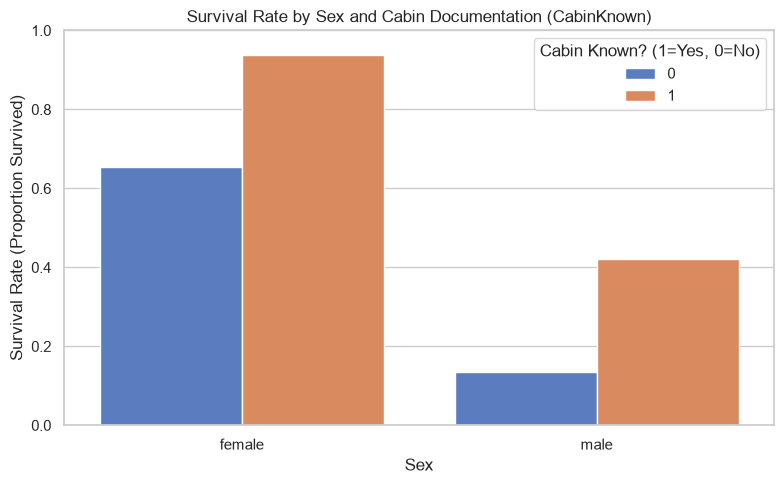

In [38]:
# Write your code here

# Grouping by Sex and CabinKnown to check passenger counts and survival rates
final_table = train.groupby(['Sex', 'CabinKnown'])['Survived'].agg(
    passenger_count='count',
    survival_rate='mean'
).reset_index()

print("--- Final Table ---")
print(final_table)

# Check that the sum of group counts equals the full training sample of 891
total_passengers = final_table['passenger_count'].sum()
print(f"\nTotal passengers: {total_passengers} (Expected: 891)")

# Create one simple chart to answer the question
plt.figure(figsize=(8, 5))
sns.barplot(
    data=final_table,
    x='Sex',
    y='survival_rate',
    hue='CabinKnown',
    palette='muted'
)

# Labeling axes and title
plt.title("Survival Rate by Sex and Cabin Documentation (CabinKnown)")
plt.xlabel("Sex")
plt.ylabel("Survival Rate (Proportion Survived)")
plt.ylim(0, 1)
plt.legend(title="Cabin Known? (1=Yes, 0=No)")
plt.tight_layout()
plt.show()


<details><summary><b>Hint 1</b></summary>

Write the question first; then decide which grouping columns answer it.

</details>

### Exercise 35 – Write your report

In a new Markdown cell, write three findings with numerical evidence, two
preparation decisions with their limitations, and one overall limitation.
At least one finding must answer your independent investigation question.
Include a warning about any very small group in your investigation.
Finish by naming one additional piece of information that would help assess your
interpretation. Save the notebook after checking it from top to bottom.

**Expected result (described, no picture or output is shown):** A written report with three supported findings, two preparation decisions and a limitation.

# Report

### 1. Three Findings with Numerical Evidence
* **Finding 1** Having a documented cabin was strongly associated with higher male survival, but male are still the dominant losses. Males with a known cabin survived at **42%** (45 of 107), compared to just **13%** (64 of 470) for males without cabin records.

* **Finding 2:** Women dominated survival regardless of cabin status,
though cabin holders still fared slightly better: **94%** survival (88 of 93) for women with documented cabins versus **65%** (145 of 221) for women without known cabins.
* **Finding 3:** The majority of passengers had missing cabin records (691 out of 891, or 77%), primarily showing they were 3rd-class passengers who never had designated cabin numbers logged in the ship manifest

### 2. Two Preparation Decisions and Their Limitations
1. **Binarizing `Cabin` into `CabinKnown` (1 vs 0):**
   * *Limitation:* It collapses all cabin decks (A, B, C, D, E) into a single flat binary flag, erasing critical distance from the boat deck and lifeboat stations
2. **Excluding children/age segmentation:**
   * *Limitation:* Lumping young boys into the `male` category dilutes the male survival rate, since boys were often allowed onto lifeboats under "women and children first."

### 3. Warning on Small Groups
* **Caution:** The subset of women with known cabins who perished is vanishingly small (only 5 out of 93 died), which makes percentages sensitive to tiny differences

### 4. Overall Limitation & Crucial Missing Information
* **Overall Limitation:** Association is not causation. A known cabin didn't save people; it acted as a proxy for passenger wealth (`Pclass = 1`) and physical cabin proximity to the open upper decks.
* **One Additional Piece of Information Needed:** The **exact physical location or lifeboat assignment number** for each passenger, which would clarify whether survival was dictated by deck evacuation order rather than ticket status.

In [39]:
# Write your code here
# :D

<details><summary><b>Hint 1</b></summary>

A useful finding states a group, a number and a comparison.

</details>
<details><summary><b>Hint 2</b></summary>

Separate observed evidence from possible explanations.

</details>

## Block 9 – Working with an LLM, critically
You may use ChatGPT, Claude, Gemini or Copilot in this course. The rule is: **you are responsible for every line and every claim**. Below are two prompts, each with a typical answer. The code runs, the output looks reasonable, and each answer is wrong in several ways that only the data can reveal.

For each exercise, do four things: (a) copy the model's code into a new cell and run it, to see its output; (b) find what is wrong, and print **a number from the data that proves each problem**; (c) in the cell below, write the corrected code; (d) write in a comment the one lesson you take from it.


### Exercise 36 – LLM answer 1: it runs, so what is wrong?

**Prompt:** *"Here are `train.csv` and `test.csv`. Clean the data and give me the survival rate by ticket class."*

The model's answer is shown below. **Run it in a new cell and look at the rates it prints.** Find **at least three** flaws, and for each one print a number that proves it (for example: how many passengers each line adds or removes, or the `n` behind a rate). Then write a corrected table with passenger count, survivor count and survival rate by `Pclass`, with **no training passenger missing**.

**Expected result (described, no picture or output is shown):** Printed numbers that prove at least three flaws, each with a short comment, followed by the corrected table for all 891 training passengers.


**Typical LLM answer. Copy it into a new cell and run it, to see its output. It reads the raw files again, so it does not use your tables; do not trust its result:**

```python
import pandas as pd

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
df = pd.concat([train_df, test_df])
df['Survived'] = df['Survived'].fillna(0)
df = df.dropna(subset=['Cabin'])
df = df.drop_duplicates(subset='Ticket')
print(df.groupby('Pclass')['Survived'].mean().round(3))
```


In [40]:
# LLM's version
import pandas as pd

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
df = pd.concat([train_df, test_df])
df['Survived'] = df['Survived'].fillna(0)
df = df.dropna(subset=['Cabin'])
df = df.drop_duplicates(subset='Ticket')
print(df.groupby('Pclass')['Survived'].mean().round(3))

# Corrected version – write your code here
# Loading data
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

# Combine them like the LLM did
combined = pd.concat([train_df, test_df])

# Flaw 1: It fills missing test Survived with 0, pretending 418 people all died
test_added_as_dead = len(test_df)
print(f"Flaw 1 - Fake deaths added from test set: {test_added_as_dead}")

# Flaw 2: Dropping rows with missing cabin wipes out most passengers
after_cabin = combined.dropna(subset=['Cabin'])
lost_to_cabin = len(combined) - len(after_cabin)
print(f"Flaw 2 - Passengers lost from missing cabin: {lost_to_cabin}")

# Flaw 3: Dropping duplicate tickets deletes family members and travel buddies
after_ticket = after_cabin.drop_duplicates(subset=['Ticket'])
lost_to_ticket = len(after_cabin) - len(after_ticket)
print(f"Flaw 3 - People deleted just for sharing a ticket: {lost_to_ticket}")

# Total n left in the LLM's broken table
print(f"Sample size left in LLM calculation: {len(after_ticket)} out of {len(combined)}")

# Corrected table: use train only, keep all 891 passengers
corrected_table = train_df.groupby('Pclass')['Survived'].agg(
    passenger_count='count',
    survivor_count='sum',
    survival_rate='mean'
).reset_index()

print("\nCorrected table:")
print(corrected_table)
print(f"\nTotal passengers check: {corrected_table['passenger_count'].sum()} (must be 891)")

Pclass
1    0.507
2    0.556
3    0.333
Name: Survived, dtype: float64
Flaw 1 - Fake deaths added from test set: 418
Flaw 2 - Passengers lost from missing cabin: 1014
Flaw 3 - People deleted just for sharing a ticket: 121
Sample size left in LLM calculation: 174 out of 1309

Corrected table:
   Pclass  passenger_count  survivor_count  survival_rate
0       1              216             136       0.629630
1       2              184              87       0.472826
2       3              491             119       0.242363

Total passengers check: 891 (must be 891)


<details><summary><b>Hint 1</b></summary>

Print the number of rows after every line of the model's code.

</details>
<details><summary><b>Hint 2</b></summary>

Exercises 1, 24 and 29 already tell you what is wrong with three of these lines.

</details>
<details><summary><b>Hint 3</b></summary>

Self-check: compare the model's rate for each class with `class_summary` from Exercise 9, and print the `n` behind each of its rates.

</details>


### Exercise 37 – LLM answer 2: the statistics, not the syntax

**Prompt:** *"Here are `train.csv` and `test.csv`. Fill the missing Age and Fare values, remove the outliers in Fare and scale both columns, so the data are ready for a model."*

The model's answer is shown below. **Run it in a new cell.** Explain **what is wrong with it statistically** (not only syntactically) and with its conclusion, and print a number that proves each problem: which rows set each learned value, what a missing fare became, how many passengers were removed and from which class, and the skewness of `Fare` before the filter, after the filter and after scaling. Then write a corrected version that follows Exercises 31–33: learn every rule on train only, apply it to both files and keep every passenger. Write one sentence on what you can and cannot conclude about the removed fares.

**Expected result (described, no picture or output is shown):** Printed numbers that prove at least three problems, each with a short comment, followed by scaled `Age` and `Fare` tables of 891 and 418 rows with no missing values, using rules learned on train.


**Typical LLM answer. Copy it into a new cell and run it, to see its output. It reads the raw files again, so it does not use your tables; do not trust its result:**

```python
import pandas as pd
from sklearn.preprocessing import StandardScaler

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
full = pd.concat([train_df, test_df], ignore_index=True)
full['Age'] = full['Age'].fillna(full['Age'].mean())
full['Fare'] = full['Fare'].fillna(0)
q1, q3 = full['Fare'].quantile([0.25, 0.75])
full = full[full['Fare'] <= q3 + 1.5 * (q3 - q1)].copy()
full[['Age', 'Fare']] = StandardScaler().fit_transform(full[['Age', 'Fare']])
print(full[['Age', 'Fare']].describe().round(3))
# Conclusion: the outliers were errors, the data are clean, and scaling made Fare normally distributed.
```


In [41]:
# Corrected version – write your code here

# Load raw files
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
full = pd.concat([train_df, test_df], ignore_index=True)

# Problem 1: Data leakage and filling missing fare with 0
print(f"Problem 1 - Rows setting the mean: {len(full)} (should be train only: {len(train_df)})")
print("Missing fare is now: 0 ")

# Skewness before any cuts
skew_before = full['Fare'].skew()

# Problem 2: Deleting valid rich passengers as outliers
q1 = full['Fare'].quantile(0.25)
q3 = full['Fare'].quantile(0.75)
cutoff = q3 + 1.5 * (q3 - q1)

dropped_people = full[full['Fare'] > cutoff]
print(f"\nProblem 2 - Passengers deleted: {len(dropped_people)}")
print("Deleted by class:\n", dropped_people['Pclass'].value_counts())

# Problem 3: Scaling does not fix skewness
filtered_fare = full[full['Fare'] <= cutoff]['Fare']
skew_filtered = filtered_fare.skew()

scaled_fare = StandardScaler().fit_transform(filtered_fare.to_frame())
skew_scaled = pd.Series(scaled_fare.ravel()).skew()

print(f"\nProblem 3 - Skewness before filter: {skew_before:.2f}")
print(f"Skewness after filter:  {skew_filtered:.2f}")
print(f"Skewness after scaling: {skew_scaled:.2f}")

# Corrected version: learn on train only, keep everyone
train_age_med = train_df['Age'].median()
train_fare_med = train_df['Fare'].median()

train_clean = train_df[['Age', 'Fare']].fillna({'Age': train_age_med, 'Fare': train_fare_med})
test_clean = test_df[['Age', 'Fare']].fillna({'Age': train_age_med, 'Fare': train_fare_med})

scaler = StandardScaler()
train_scaled = pd.DataFrame(scaler.fit_transform(train_clean), columns=['Age', 'Fare'])
test_scaled = pd.DataFrame(scaler.transform(test_clean), columns=['Age', 'Fare'])

print(f"\nFinal row check: Train={len(train_scaled)} (891), Test={len(test_scaled)} (418)")
print(f"Missing values: Train={train_scaled.isna().sum().sum()}, Test={test_scaled.isna().sum().sum()}")

# We can conclude these high fares were legitimate luxury suites, but we cannot conclude they were data errors just because they were expensive.

Problem 1 - Rows setting the mean: 1309 (should be train only: 891)
Missing fare is now: 0 

Problem 2 - Passengers deleted: 171
Deleted by class:
 Pclass
1    153
3     11
2      7
Name: count, dtype: int64

Problem 3 - Skewness before filter: 4.37
Skewness after filter:  1.49
Skewness after scaling: 1.49

Final row check: Train=891 (891), Test=418 (418)
Missing values: Train=0, Test=0


<details><summary><b>Hint 1</b></summary>

Which rows were used to compute each value the model fills in or fits?

</details>
<details><summary><b>Hint 2</b></summary>

Is 0 already a recorded value in `Fare`? Who is removed by the fare filter?

</details>
<details><summary><b>Hint 3</b></summary>

To test the conclusion, compare `.skew()` of `Fare` at each step. Which step changes it?

</details>


## Block 10 – Further investigations ★ (extra)

Every exercise in this block is marked with ★: they are extra, for whoever finishes early. They add a random-age comparison and extend the ticket and fare-band work. Compare each result with the main exercises and explain any change in assumptions.

### Exercise 38 – Random age imputation ★

On a fresh copy of `train_raw`, try sampling
ages uniformly between the observed mean minus one standard deviation and mean
plus one standard deviation. Use seed 42 and then seed 43; fill only missing ages.
Compare the completed means and explain why reproducibility does not establish
that a uniform distribution is an appropriate age model.
For seed 42, draw observed ages and the completed ages side by side using identical 5-year bins, and show missing-value maps before and after. Preserve fractional observed ages.

Original observed mean age: 29.69911764705882
Completed mean with seed 42: 29.536725123437307
Completed mean with seed 43: 29.758342974366485


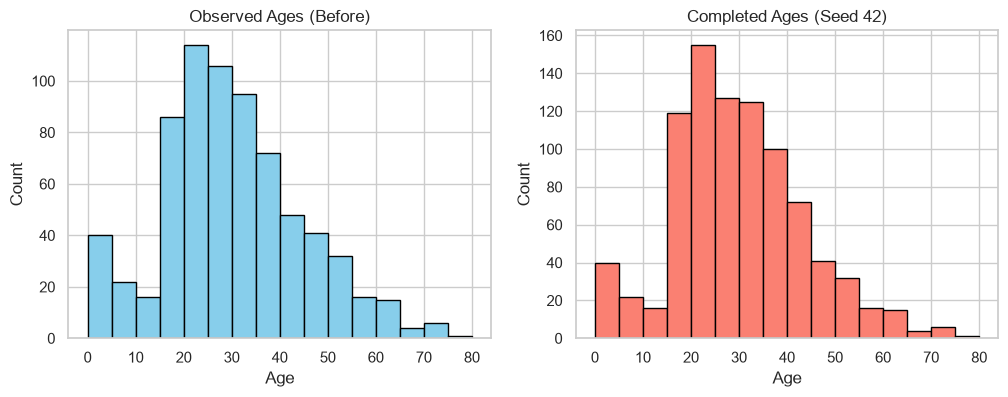

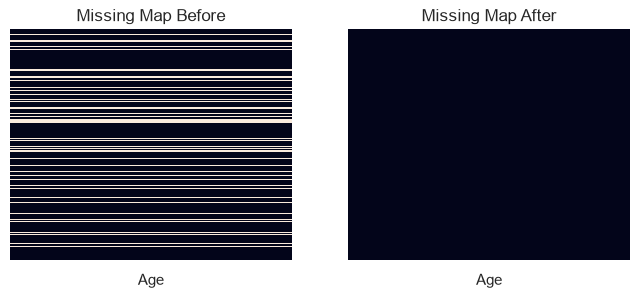

In [42]:
# Write your code here
train_copy = train_raw.copy(deep=True)

# Observed age statistics
age_mean = train_copy['Age'].mean()
age_std = train_copy['Age'].std()
low = age_mean - age_std
high = age_mean + age_std
num_missing = train_copy['Age'].isna().sum()

# Sample uniformly with seed 42 and seed 43
np.random.seed(42)
ages_seed_42 = np.random.uniform(low, high, size=num_missing)
np.random.seed(43)
ages_seed_43 = np.random.uniform(low, high, size=num_missing)

# Completed series for both seeds
completed_42 = train_copy['Age'].copy()
completed_42[completed_42.isna()] = ages_seed_42
completed_43 = train_copy['Age'].copy()
completed_43[completed_43.isna()] = ages_seed_43

print("Original observed mean age:", age_mean)
print("Completed mean with seed 42:", completed_42.mean())
print("Completed mean with seed 43:", completed_43.mean())

# Plot side-by-side using 5-year bins
bin_edges = np.arange(0, train_copy['Age'].max() + 5, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train_copy['Age'].dropna(), bins=bin_edges, edgecolor='black', color='skyblue')
axes[0].set_title('Observed Ages (Before)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

axes[1].hist(completed_42, bins=bin_edges, edgecolor='black', color='salmon')
axes[1].set_title('Completed Ages (Seed 42)')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')
plt.show()

# Missing-value maps before and after
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
sns.heatmap(train_copy[['Age']].isna(), cbar=False, ax=axes[0], yticklabels=False)
axes[0].set_title('Missing Map Before')

sns.heatmap(completed_42.to_frame().isna(), cbar=False, ax=axes[1], yticklabels=False)
axes[1].set_title('Missing Map After')
plt.show()

# Why reproducibility does not mean uniform is appropriate:
# A fixed random seed just makes identical numbers reproducible across runs.
# It doesn't mean human ages are flat and uniform; real ages are skewed and non-uniform.

<details><summary><b>Hint 1</b></summary>

Use an independent random generator for each seed.

</details>

### Exercise 39 – How stable is ticket frequency across samples? ★

Exercise 25 counted tickets within
train. On a separate copy of test, compare frequencies counted in test with
frequencies mapped from train. Count how many test passengers have a ticket code
not seen in train. Explain why an unseen ticket is not evidence that its passenger travelled
alone, and why recomputing frequencies in each file defines different information.
Do not add test observations to the survival analysis.

In [43]:
# Write your code here
# Separate copy of test
test_tickets = test.copy(deep=True)

# Count frequencies in test itself
test_tickets['Freq_in_test'] = test_tickets['Ticket'].map(test_tickets['Ticket'].value_counts())

# Map frequencies learned from train
test_tickets['Freq_from_train'] = test_tickets['Ticket'].map(org_train['Ticket'].value_counts())

# Count test passengers with tickets never seen in train
unseen_tickets = test_tickets['Freq_from_train'].isna()
print("Test passengers with tickets unseen in train:", unseen_tickets.sum())

# Why unseen ticket oisnt equal to traveling alone:
# A passenger's companions might be in test.csv, or their family members weren't in the train split.
# Recomputing frequencies inside each file separately measures "cohort sample density"
# rather than true shipboard traveling-party size.

Test passengers with tickets unseen in train: 266


<details><summary><b>Hint 1</b></summary>

Map counts learned in train to the test ticket codes.

</details>
<details><summary><b>Hint 2</b></summary>

Count passenger rows with an unknown mapped frequency, not unique ticket codes.

</details>

### Exercise 40 – Apply the training fare bands to test ★

Use the `fare_band_edges` learned in Exercise 26 to group test fares, after filling the missing fare with the training
median. Do not learn new quantiles from test. Report group counts and any fares
outside the training edges. Explain what policy would be needed for future fares
outside those edges, without silently changing the rule.

In [44]:
# Write your code here
test_fare = test.copy(deep=True)

# Fill missing test fare using train median
test_fare['Fare'] = test_fare['Fare'].fillna(train_raw['Fare'].median())

# Group test fares using the learned edges from Exercise 26
test_fare['FareBand'] = pd.cut(test_fare['Fare'], bins=fare_band_edges, include_lowest=True)

print("Test group counts by training fare bands:")
print(test_fare['FareBand'].value_counts(dropna=False).sort_index())

# Check for fares outside the learned boundaries
outside_edges = (test_fare['Fare'] < fare_band_edges[0]) | (test_fare['Fare'] > fare_band_edges[-1])
print("Test fares strictly outside training edges:", outside_edges.sum())

# Policy needed for future fares outside edges:
# Fares exceeding the top boundary should be clamped into the highest band (open-ended upper bound),
# and negative fares should be rejected or clamped to zero, avoiding silent NaN drops.

Test group counts by training fare bands:
FareBand
(-0.001, 7.91]     114
(7.91, 14.454]      97
(14.454, 31.0]      99
(31.0, 512.329]    108
Name: count, dtype: int64
Test fares strictly outside training edges: 0


<details><summary><b>Hint 1</b></summary>

Use pd.cut with the already learned fare_band_edges and include the lowest boundary.

</details>
<details><summary><b>Hint 2</b></summary>

Do not call qcut on test; check whether any observed fares fall outside the learned boundaries.

</details>

# **Good Job :)**

Save the notebook, make sure every cell runs top to bottom (Kernel ▸ Restart & Run All), and submit.